# Retail Trade Sales Forecasting — South Africa (Corrected-Data Re-run)

Machine-learning vs econometric models for short-term forecasting of **Total retail
trade sales, constant 2019 prices, not seasonally adjusted** (Stats SA, P6242.1),
Jan 1986 – May 2026. Supervisor-revision re-run on the **corrected** dataset.

**Run on Google Colab** (mounts Drive below). Each model is fitted in its own cell and
evaluated on the fixed Jan–May 2026 holdout (Section 4). The rolling-origin walk-forward
that carries all statistical inference — with ARIMA/SARIMAX re-estimated at every origin —
is Section 5. SHAP explainability is Section 7.

In [1]:
"""
=============================================================================
STRUCTURE
=============================================================================
SECTION 0  : Google Drive mount + install
SECTION 1  : Data loading, EDA-informed feature engineering & preprocessing
SECTION 2  : Train / holdout split (Train <= Dec 2025 | Holdout = Jan-May 2026,
             forecast from a FIXED Dec-2025 origin, direct multi-step h=1..5)
SECTION 3  : Metric helper + direct multi-step fitter (raw-level target for trees)
SECTION 4  : Model fitting on the holdout (each model in its own cell)
             4-pre Naive & Seasonal Naive | 4a ARIMA | 4b SARIMAX
             4c XGBoost | 4d Random Forest | 4e LightGBM | 4f Ensemble | 4g table
SECTION 5  : Rolling-origin walk-forward validation (ALL inference lives here)
             5a run | 5b MAPE vs MdAPE | 5c Diebold-Mariano | 5d ablation
             5e conformal: rolling-origin COVERAGE + 2026 holdout INTERVALS
SECTION 6  : CPI robustness (inflation vs level)
SECTION 7  : Explainability
             7a) Native feature importance (XGBoost / RF / LightGBM, avg over h)
             7b) SHAP (LightGBM beeswarm + Dec-2025 waterfall)

=============================================================================
DESIGN DECISIONS & JUSTIFICATIONS  (updated for the corrected dataset)
=============================================================================

[D0] CORRECTED TARGET -- Total retail sales, constant 2019 prices, NSA
  The previous target averaged every category row of the Stats SA files because
  the H01-H05 label columns were dropped, blending constant/current prices,
  seasonally-adjusted/not, and totals/sub-categories -- producing a spurious ~10x
  block in 2004. The corrected series selects the single published Total row
  (constant prices, NSA) and growth-splices the 1995->2019 base change; it matches
  the official Stats SA P6242.1 (May 2026) release exactly (Dec 2025 = 138,834;
  Jan-May 2026 = 97,326/95,209/99,422/96,677/101,008). A mild seasonality difference
  exists across the 2002 survey redesign (Dec/annual ~1.47 pre-2002 vs ~1.38 from
  2002) and is disclosed in the paper.

[D1] MODEL SELECTION -- ARIMA, SARIMAX, RANDOM FOREST, XGBOOST, LIGHTGBM
  Classical econometric baselines (Box & Jenkins, 1976; Aye et al., 2015) vs tree
  ensembles (Breiman, 2001; Chen & Guestrin, 2016; Ke et al., 2017), which won the
  M5 retail competition (Makridakis et al., 2022).

[D2] OUTLIER TREATMENT -- LIGHT, ORIGIN-RELATIVE WINSORISATION (revised)
  The earlier Jan-2004 outlier (z=21.6) was a DATA ARTIFACT, now fixed at source.
  On corrected data the only extreme is the real May-2020 COVID rebound (z~5.1).
  Winsorisation is light, train-only per origin ([1%,99%]), and can be switched
  off via USE_WINSOR (Tukey, 1962).

[D3] SEASONAL FEATURES -- month/quarter + is_dec/is_nov/is_apr (Hyndman &
  Athanasopoulos, 2021; Cerqueira et al., 2020).

[D4] NO STRUCTURAL-BREAK DUMMY (revised) -- the old Dec-2003 break was the 2004
  artifact; none exists on the corrected series.

[D5] LAG & ROLLING FEATURES -- lags 1/3/6/12, rolling mean 3/6, rolling std 6;
  lag-12 anchors the seasonal cycle (Bontempi et al., 2013). Rolling features use
  shift(1) so no contemporaneous value leaks in.

[D5b] TREE TARGET -- RAW LEVEL (like-for-like comparison; TREE_TARGET='level')
  All models forecast the raw level of retail trade sales so that the ML-vs-
  econometric comparison is on an identical, untransformed target. The tree
  ensembles are trained directly on y_{t+h} via the direct multi-step scheme
  (one model per horizon), with the same feature set used throughout.
  KNOWN TRADE-OFF: the corrected series trends strongly (R37k->R138k) and tree
  ensembles interpolate within feature-similar training rows, which for a trending
  series are historically lower, so on the level target the trees tend to under-
  forecast at recent highs and are competitive-but-not-dominant against the strong
  seasonal-naive benchmark. A stationary reformulation (year-on-year ratio,
  TREE_TARGET='ratio') removes this and improves the trees, mirroring how ARIMA
  differences the series; it is provided as an option but NOT used here so that
  every model is compared on the raw level (Bontempi et al., 2013; Hyndman &
  Athanasopoulos, 2021).

[D6] HOLDOUT -- FIXED Dec-2025 ORIGIN, DIRECT MULTI-STEP h=1..5 (revised)
  Jan-May 2026 (5 months) is the completely unseen final test period; never used
  for selection/screening/tuning. Forecast from a SINGLE Dec-2025 origin at h=1..5
  (direct multi-step) -- no rolling within the holdout, no error carry-over.
  Oct-Dec 2025 returns to the training pool. Covariates are frozen after Dec 2025,
  so ML uses only Dec-2025-and-earlier features and SARIMAX projects exog from
  train-only data. Statistical inference is Section 5, not these 5 points.

[D7] METRICS -- RMSE, MAE, MAPE, MdAPE, sMAPE, R2. MAPE = MEAN APE (inflated by
  rare shock months); MdAPE = MEDIAN APE (typical accuracy). Both reported
  (Makridakis et al., 2018/2020; Hyndman & Koehler, 2006).

[D8] ARIMA (1,1,1); [D9] SARIMAX (1,1,1)(0,1,1,12) -- d=1 (ADF level p=0.97,
  diff p<0.001); seasonal differencing for annual seasonality.

[D10] SARIMAX EXOG SCREEN -- |r|>=0.15 AND CV<=2.0, TRAIN-ONLY per origin (Cohen,
  1988; Makridakis et al., 1998; collinear vars reduced, Hair et al., 2019).

[D10b] CPI AS YEAR-ON-YEAR INFLATION, NOT LEVEL (new) -- on a real target the CPI
  level is ~0.98 correlated with the trend (a trend proxy re-introducing removed
  inflation); inflation carries the genuine negative demand signal (r~-0.55).
  CPI_MODE='level' reruns the level as a robustness check (Section 6).

[D11] EXOG PROJECTION -- capped OLS trend on trailing 12 (+/-3 sigma).
[D12] DIRECT MULTI-STEP (h=1..5) -- independent per-horizon models avoid recursive
  error compounding (Chevillon, 2007; Ben Taieb et al., 2012).
[D13-15] ML HYPERPARAMETERS -- fixed, conservative (no tuning). XGBoost depth 3;
  RF depth 10, min_leaf 5; LightGBM depth 4, leaves 15; lr 0.03, 500 trees, 0.8
  subsample, L1/L2 0.1/1.0.
[D16] ENSEMBLE -- equal-weight top-2 by RMSE (Timmermann, 2006).

[D17] WALK-FORWARD -- ROLLING-ORIGIN, ARIMA/SARIMAX RE-ESTIMATED PER ORIGIN
  (revised). At each origin winsorisation bounds and the SARIMAX screen use
  train-only data, and both econometric models are refit; ML uses direct
  multi-step on the raw level (TREE_TARGET). ~300 origins x h=1..5 gives the statistical
  power the 5-point holdout lacks (Tashman, 2000; Bergmeir & Benitez, 2012).

[D20] DIEBOLD-MARIANO -- HLN-modified (Harvey et al., 1997) on rolling-origin
  squared-error losses, per horizon, vs Seasonal Naive AND vs SARIMAX.

[D21] ABLATION -- leave-one-group-out on the ROLLING-ORIGIN MdAPE (revised).

[D22] CONFORMAL -- split-conformal for the best-performing ML model (auto-selected
  from the walk-forward, or CONFORMAL_MODEL). EMPIRICAL COVERAGE is measured
  ACROSS ALL ROLLING ORIGINS (per horizon and pooled), and prediction INTERVALS
  are produced for the Jan-May 2026 holdout (Vovk et al., 2005; Lei et al., 2018;
  Stankeviciute et al., 2021; Barber et al., 2023).

[D18] EXPLAINABILITY -- (7a) native tree feature importance (gain/impurity) for
  XGBoost/RF/LightGBM, averaged across horizons, shows which features each model
  USES most; (7b) SHAP TreeExplainer beeswarm (global, with direction) + waterfall
  (Dec-2025 forecast) on the LightGBM level model shows DIRECTION and magnitude of
  each contribution. Native importance and SHAP are complementary (Lundberg & Lee,
  2017; Buckmann et al., 2021).

References: Aye et al. (2015); Masena et al. (2024); Box & Jenkins (1976); Breiman
(2001); Chen & Guestrin (2016); Ke et al. (2017); Hyndman & Athanasopoulos (2021);
Makridakis et al. (2018/2020/2022); Diebold & Mariano (1995); Harvey, Leybourne &
Newbold (1997); Tashman (2000); Bergmeir & Benitez (2012); Cerqueira et al. (2020);
Chevillon (2007); Ben Taieb et al. (2012); Bontempi et al. (2013); Timmermann
(2006); Vovk et al. (2005); Lei et al. (2018); Stankeviciute et al. (2021); Barber
et al. (2023); Lundberg & Lee (2017); Tukey (1962); Cohen (1988).
=============================================================================
"""

"\n=============================================================================\nSTRUCTURE\n=============================================================================\nSECTION 0  : Google Drive mount + install\nSECTION 1  : Data loading, EDA-informed feature engineering & preprocessing\nSECTION 2  : Train / holdout split (Train <= Dec 2025 | Holdout = Jan-May 2026,\n             forecast from a FIXED Dec-2025 origin, direct multi-step h=1..5)\nSECTION 3  : Metric helper + direct multi-step fitter (raw-level target for trees)\nSECTION 4  : Model fitting on the holdout (each model in its own cell)\n             4-pre Naive & Seasonal Naive | 4a ARIMA | 4b SARIMAX\n             4c XGBoost | 4d Random Forest | 4e LightGBM | 4f Ensemble | 4g table\nSECTION 5  : Rolling-origin walk-forward validation (ALL inference lives here)\n             5a run | 5b MAPE vs MdAPE | 5c Diebold-Mariano | 5d ablation\n             5e conformal: rolling-origin COVERAGE + 2026 holdout INTERVALS\nSECTION 6 

In [2]:
# ─── SECTION 0 : GOOGLE COLAB — MOUNT GOOGLE DRIVE ───────────────────────────
import os

try:
    from google.colab import drive
    IN_COLAB = True
    print("Detected Google Colab environment — mounting Google Drive ...")
    drive.mount("/content/drive", force_remount=False)

    # ── EDIT THESE TWO LINES ───────────────────────────────────────────────────
    DATA_PATH  = "/content/drive/MyDrive/MIT807 Project/final_model_dataset_corrected.csv"
    OUTPUT_DIR = "/content/drive/MyDrive/MIT807 Project/outputs"
    # ───────────────────────────────────────────────────────────────────────────

    os.makedirs(OUTPUT_DIR, exist_ok=True)
    os.chdir(OUTPUT_DIR)

except ImportError:
    IN_COLAB = False
    DATA_PATH  = "final_model_dataset_corrected.csv"
    OUTPUT_DIR = "."
    print("Not in Google Colab — using local working directory.")

print("DATA_PATH  =", DATA_PATH)
print("OUTPUT_DIR =", OUTPUT_DIR)

Detected Google Colab environment — mounting Google Drive ...
Mounted at /content/drive
DATA_PATH  = /content/drive/MyDrive/MIT807 Project/final_model_dataset_corrected.csv
OUTPUT_DIR = /content/drive/MyDrive/MIT807 Project/outputs


In [3]:
# ─── SECTION 0 : INSTALL (run once if missing) ───────────────────────────────
import importlib, subprocess, sys
for package in ["statsmodels", "xgboost", "lightgbm", "scikit-learn", "scipy", "shap"]:
    module = "sklearn" if package == "scikit-learn" else package
    try:
        importlib.import_module(module)
    except ImportError:
        print(f"installing {package} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package, "-q"])
print("dependencies ready")

dependencies ready


In [4]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from statsmodels.tsa.arima.model import ARIMA
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from scipy import stats
import shap

# ── Global configuration ─────────────────────────────────────────────────────
HORIZONS          = [1, 2, 3, 4, 5]   # holdout = Jan..May 2026 from the Dec-2025 origin
LAST_TRAIN_DATE   = "2025-12-31"      # Dec-2025 origin (training uses <= this date)
CPI_MODE          = "yoy"             # 'yoy' = inflation (recommended) | 'level' = robustness
USE_WINSOR        = True              # light, origin-relative [1%,99%] growth winsorisation
FIRST_ORIGIN_DATE = "2000-01-31"      # first rolling origin (Section 5); '2005-01-31' = faster
TREE_TARGET       = "level"           # [D5b] 'level' (all models on raw sales) or 'ratio'
CONFORMAL_MODEL   = "auto"            # [D22] 'auto' = best tree by walk-forward MdAPE, or name it
print("config set | horizons", HORIZONS, "| CPI_MODE", CPI_MODE, "| TREE_TARGET", TREE_TARGET)

config set | horizons [1, 2, 3, 4, 5] | CPI_MODE yoy | TREE_TARGET level


In [5]:
# ─── Package versions (for the paper's reproducibility statement) ───────────
import sys, statsmodels, xgboost, lightgbm, sklearn
print("Python      ", sys.version.split()[0])
print("statsmodels ", statsmodels.__version__)
print("xgboost     ", xgboost.__version__)
print("lightgbm    ", lightgbm.__version__)
print("scikit-learn", sklearn.__version__)

Python       3.13.16
statsmodels  0.15.0
xgboost      3.4.1
lightgbm     4.6.0
scikit-learn 1.6.1


In [6]:
# ─── SECTION 1 : DATA LOADING, FEATURE ENGINEERING & PREPROCESSING ───────────
print("=" * 65); print("SECTION 1 — Data loading & feature engineering"); print("=" * 65)

source_data = pd.read_csv(DATA_PATH, sep=";")
source_data["date"] = pd.to_datetime(source_data["date"])
source_data = source_data.set_index("date").sort_index()
TARGET_COL = "retail_sales"

# Modelling frame. Lags/rolling use only past values (rolling via shift(1)).
data = pd.DataFrame(index=source_data.index)
data[TARGET_COL] = source_data[TARGET_COL]

# [D3] calendar / seasonal features
data["month"]       = source_data.index.month
data["quarter"]     = source_data.index.quarter
data["is_december"] = (source_data.index.month == 12).astype(int)
data["is_november"] = (source_data.index.month == 11).astype(int)   # Black Friday lift
data["is_april"]    = (source_data.index.month ==  4).astype(int)   # post-festive trough
data["trend"]       = np.arange(len(source_data))

# [D5] lag & rolling features
data["retail_lag_1"]     = source_data[TARGET_COL].shift(1)
data["retail_lag_3"]     = source_data[TARGET_COL].shift(3)
data["retail_lag_6"]     = source_data[TARGET_COL].shift(6)
data["retail_lag_12"]    = source_data[TARGET_COL].shift(12)              # seasonal anchor
data["retail_roll_3"]    = source_data[TARGET_COL].shift(1).rolling(3).mean()
data["retail_roll_6"]    = source_data[TARGET_COL].shift(1).rolling(6).mean()
data["retail_roll_std6"] = source_data[TARGET_COL].shift(1).rolling(6).std()
data["retail_growth"]    = source_data[TARGET_COL].pct_change()

# [D10b] CPI as year-on-year inflation (not level) on a real target
data["cpi_signal"]    = (source_data["cpi"].pct_change(12) * 100) if CPI_MODE == "yoy" else source_data["cpi"]
data["electricity"]   = source_data["electricity"]
data["exchange_rate"] = source_data["exchangeRate"]
data["cci_level"]     = source_data["cci_level"]

# [D-lag] Publication-lag alignment: at origin t, use only data released by t.
# CPI (StatsSA P0141, released ~mid of t+1) -> lag 1 ; electricity (P4141, released ~start of t+2) -> lag 2 ;
# the exchange rate is a daily market price -> no lag ; quarterly CCI is carried forward between releases.
CPI_PUB_LAG, ELEC_PUB_LAG = 1, 2
data["cpi_signal"]  = data["cpi_signal"].shift(CPI_PUB_LAG)
data["electricity"] = data["electricity"].shift(ELEC_PUB_LAG)
data["cci_level"]   = data["cci_level"].ffill()

# [D4] No structural-break dummy on corrected data (old break was the 2004 artifact).

print(f"Rows (incl. 2026 holdout): {len(data)}  | {data.index.min().date()} -> {data.index.max().date()}")
print(f"Target: constant 2019 prices, NSA. CPI as: {'YoY inflation' if CPI_MODE=='yoy' else 'level'}. "
      f"Tree target: {TREE_TARGET}.")
print(f"Holdout actuals (Jan-May 2026): {source_data.loc['2026-01-31':'2026-05-31', TARGET_COL].round(0).tolist()}")

SECTION 1 — Data loading & feature engineering
Rows (incl. 2026 holdout): 485  | 1986-01-31 -> 2026-05-31
Target: constant 2019 prices, NSA. CPI as: YoY inflation. Tree target: level.
Holdout actuals (Jan-May 2026): [97326.0, 95209.0, 99422.0, 96677.0, 101008.0]


In [7]:
# ─── SECTION 2 : TRAIN / TEST SPLIT ──────────────────────────────────────────
print("\n" + "=" * 65); print("SECTION 2 — Train / holdout split"); print("=" * 65)

# [D6] Training = up to the Dec-2025 origin; Holdout = Jan-May 2026 (h=1..5 from origin).
origin_date     = pd.Timestamp(LAST_TRAIN_DATE)
train_data      = data.loc[:origin_date]
holdout_data    = data.loc["2026-01-01":"2026-05-31"]
origin_pos      = data.index.get_loc(origin_date)
target_series   = data[TARGET_COL]
holdout_actuals = {horizon: float(target_series.iloc[origin_pos + horizon]) for horizon in HORIZONS}

# [D2] light, origin-relative winsorisation of the growth feature (train-only bounds)
if USE_WINSOR:
    winsor_lo, winsor_hi = train_data["retail_growth"].quantile([0.01, 0.99])
    data["retail_growth_winsor"] = data["retail_growth"].clip(winsor_lo, winsor_hi)
    print(f"Winsor bounds (train-only): [{winsor_lo:.3f}, {winsor_hi:.3f}]  (mainly clips the real COVID month)")
else:
    data["retail_growth_winsor"] = data["retail_growth"]

print(f"Train  : {train_data.index.min().date()} -> {train_data.index.max().date()}  ({len(train_data)} rows)")
print(f"Holdout: {holdout_data.index.min().date()} -> {holdout_data.index.max().date()}  "
      f"({len(holdout_data)} rows), h=1..5 from {origin_date.date()}")

FEATURE_COLS = ["month", "quarter", "is_december", "is_november", "is_april", "trend",
                "retail_lag_1", "retail_lag_3", "retail_lag_6", "retail_lag_12",
                "retail_roll_3", "retail_roll_6", "retail_roll_std6", "retail_growth_winsor",
                "cpi_signal", "electricity", "exchange_rate", "cci_level"]
print(f"ML features ({len(FEATURE_COLS)}): {FEATURE_COLS}")


SECTION 2 — Train / holdout split
Winsor bounds (train-only): [-0.401, 0.440]  (mainly clips the real COVID month)
Train  : 1986-01-31 -> 2025-12-31  (480 rows)
Holdout: 2026-01-31 -> 2026-05-31  (5 rows), h=1..5 from 2025-12-31
ML features (18): ['month', 'quarter', 'is_december', 'is_november', 'is_april', 'trend', 'retail_lag_1', 'retail_lag_3', 'retail_lag_6', 'retail_lag_12', 'retail_roll_3', 'retail_roll_6', 'retail_roll_std6', 'retail_growth_winsor', 'cpi_signal', 'electricity', 'exchange_rate', 'cci_level']


In [8]:
# ─── SECTION 3 : METRIC HELPER & DIRECT MULTI-STEP FITTER ────────────────────
def evaluate_forecast(actual_values, predicted_values, model_name):
    """[D7] RMSE, MAE, MAPE (mean), MdAPE (median), sMAPE, R2 over the holdout vector."""
    actual_values    = np.asarray(actual_values, float)
    predicted_values = np.asarray(predicted_values, float)
    abs_pct_error = np.abs((actual_values - predicted_values) /
                           np.where(actual_values == 0, 1, actual_values)) * 100
    rmse  = np.sqrt(mean_squared_error(actual_values, predicted_values))
    mae   = mean_absolute_error(actual_values, predicted_values)
    mape  = abs_pct_error.mean()
    mdape = np.median(abs_pct_error)
    smape = 100 * np.mean(2 * np.abs(predicted_values - actual_values) /
                          (np.abs(actual_values) + np.abs(predicted_values)))
    r2    = r2_score(actual_values, predicted_values) if len(actual_values) > 1 else np.nan
    print(f"  {model_name:<26s} RMSE={rmse:>9,.1f}  MAE={mae:>9,.1f}  "
          f"MAPE={mape:>6.2f}%  MdAPE={mdape:>6.2f}%  sMAPE={smape:>6.2f}%  R2={r2:>7.4f}")
    return {"Model": model_name, "RMSE": rmse, "MAE": mae, "MAPE": mape,
            "MdAPE": mdape, "sMAPE": smape, "R2": r2}


def fit_direct_multistep(model_factory, frame, feature_cols, origin_position,
                         horizons=HORIZONS, tree_target=TREE_TARGET, verbose=False,
                         return_h1_model=False):
    """[D12/D5b] Fit ONE model per horizon on (X_t, target_{t+h}) with t+h <= origin;
       predict from X_origin. With tree_target='ratio' the model learns the year-on-year
       growth factor y_{t+h}/y_{t+h-12} and the level is reconstructed with the known
       anchor y_{origin+h-12}. Returns {horizon: forecast}; optionally the fitted h=1
       model + its training matrix (for SHAP)."""
    feature_matrix = frame[feature_cols]
    target_values  = frame[TARGET_COL].values
    n_rows = len(frame)
    forecast_by_horizon = {}
    h1_model = None; h1_train_matrix = None
    for horizon in horizons:
        train_positions = [i for i in range(n_rows)
                           if i + horizon <= origin_position
                           and i + horizon - 12 >= 0
                           and feature_matrix.iloc[i].notna().all()
                           and not np.isnan(target_values[i + horizon])]
        anchor_train = np.array([target_values[i + horizon - 12] for i in train_positions])
        level_train  = target_values[[i + horizon for i in train_positions]]
        fit_target   = level_train / anchor_train if tree_target == "ratio" else level_train

        model = model_factory()
        train_matrix = feature_matrix.iloc[train_positions].values
        model.fit(train_matrix, fit_target)

        raw_prediction = float(model.predict(feature_matrix.iloc[[origin_position]].values)[0])
        anchor_origin  = target_values[origin_position + horizon - 12]
        forecast_by_horizon[horizon] = (raw_prediction * anchor_origin
                                        if tree_target == "ratio" else raw_prediction)
        if verbose:
            print(f"      h={horizon}: fit on {len(train_positions)} pairs "
                  f"({tree_target} target) -> forecast {forecast_by_horizon[horizon]:,.0f}")
        if horizon == 1:
            h1_model, h1_train_matrix = model, feature_matrix.iloc[train_positions]
    if return_h1_model:
        return forecast_by_horizon, h1_model, h1_train_matrix
    return forecast_by_horizon


# model constructors [D13-15]
def make_xgboost():
    return XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=3, subsample=0.8,
                        colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
                        random_state=42, n_jobs=2, verbosity=0)

def make_random_forest():
    return RandomForestRegressor(n_estimators=500, max_depth=10, min_samples_leaf=5,
                                 random_state=42, n_jobs=2)

def make_lightgbm():
    return LGBMRegressor(n_estimators=500, learning_rate=0.03, max_depth=4, num_leaves=15,
                         subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
                         random_state=42, n_jobs=2, verbose=-1)

holdout_results = []
tree_model_factories = {"XGBoost": make_xgboost, "RandomForest": make_random_forest, "LightGBM": make_lightgbm}
print("Section 3 helpers ready.  Tree target =", TREE_TARGET)

Section 3 helpers ready.  Tree target = level


In [9]:
# ─── SECTION 4 : MODEL FITTING (holdout = Jan-May 2026 from Dec-2025 origin) ──
print("=" * 65); print("SECTION 4 — Model fitting on the holdout"); print("=" * 65)

# [D19] Naive & Seasonal Naive baselines -- the floor every model must beat.
print("\n[4-pre] Naive baselines ...")
last_observed_value = float(target_series.iloc[origin_pos])
naive_forecast          = {horizon: last_observed_value for horizon in HORIZONS}
seasonal_naive_forecast = {horizon: float(target_series.iloc[origin_pos + horizon - 12]) for horizon in HORIZONS}
print(f"   Naive (last value = {last_observed_value:,.0f}); Seasonal Naive uses Jan-May 2025:")
for horizon in HORIZONS:
    print(f"     h={horizon} ({data.index[origin_pos + horizon].strftime('%b %Y')}): "
          f"SNaive={seasonal_naive_forecast[horizon]:,.0f}  actual={holdout_actuals[horizon]:,.0f}")
holdout_results.append(evaluate_forecast([holdout_actuals[h] for h in HORIZONS],
                                         [naive_forecast[h] for h in HORIZONS], "Naive"))
holdout_results.append(evaluate_forecast([holdout_actuals[h] for h in HORIZONS],
                                         [seasonal_naive_forecast[h] for h in HORIZONS], "SeasonalNaive"))

SECTION 4 — Model fitting on the holdout

[4-pre] Naive baselines ...
   Naive (last value = 138,834); Seasonal Naive uses Jan-May 2025:
     h=1 (Jan 2026): SNaive=93,239  actual=97,326
     h=2 (Feb 2026): SNaive=93,708  actual=95,209
     h=3 (Mar 2026): SNaive=97,009  actual=99,422
     h=4 (Apr 2026): SNaive=95,554  actual=96,677
     h=5 (May 2026): SNaive=98,774  actual=101,008
  Naive                      RMSE= 40,957.0  MAE= 40,905.6  MAPE= 41.83%  MdAPE= 42.65%  sMAPE= 34.57%  R2=-397.6624
  SeasonalNaive              RMSE=  2,491.2  MAE=  2,271.6  MAPE=  2.32%  MdAPE=  2.21%  sMAPE=  2.35%  R2=-0.4749


In [10]:
# ─── SECTION 4a : ARIMA (1,1,1) ──────────────────────────────────────────────
print("\n[4a] ARIMA(1,1,1) — fitting on training <= Dec 2025 ...")
arima_model = ARIMA(train_data[TARGET_COL].astype(float), order=(1, 1, 1)).fit()
arima_raw_forecast = arima_model.forecast(max(HORIZONS))
arima_forecast = {horizon: float(arima_raw_forecast.iloc[horizon - 1]) for horizon in HORIZONS}
print(f"   fitted on {len(train_data)} obs; AIC={arima_model.aic:,.1f}")
holdout_results.append(evaluate_forecast([holdout_actuals[h] for h in HORIZONS],
                                         [arima_forecast[h] for h in HORIZONS], "ARIMA"))


[4a] ARIMA(1,1,1) — fitting on training <= Dec 2025 ...
   fitted on 480 obs; AIC=10,128.4
  ARIMA                      RMSE=  8,083.9  MAE=  7,331.8  MAPE=  7.55%  MdAPE=  7.46%  sMAPE=  7.21%  R2=-14.5306


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


In [11]:
# ─── SECTION 4b : SARIMAX (1,1,1)(0,1,1,12) with origin-relative exog screen ──
print("\n[4b] SARIMAX(1,1,1)(0,1,1,12) with EDA/train-screened exog ...")
EXOG_CANDIDATES = ["cpi_signal", "electricity", "exchange_rate", "cci_level"]
retained_exog = []
for candidate in EXOG_CANDIDATES:                                  # [D10] train-only screen
    candidate_series = train_data[candidate]
    if candidate_series.notna().sum() < 60:
        continue
    correlation = np.corrcoef(candidate_series.fillna(candidate_series.mean()), train_data[TARGET_COL])[0, 1]
    coef_var    = abs(candidate_series.std() / candidate_series.mean()) if candidate_series.mean() != 0 else np.inf
    passed = abs(correlation) >= 0.15 and coef_var <= 2.0
    print(f"   {candidate:<14s} |r|={abs(correlation):.3f}  CV={coef_var:.3f}  -> {'KEEP' if passed else 'drop'}")
    if passed:
        retained_exog.append(candidate)

if retained_exog:
    exog_train = train_data[retained_exog].ffill().bfill()
    exog_projection = {}                                           # [D11] capped OLS trend
    for candidate in retained_exog:
        recent_tail = exog_train[candidate].iloc[-12:].values
        trend_coef  = np.polyfit(np.arange(12), recent_tail, 1)
        projected   = np.polyval(trend_coef, np.arange(12, 12 + max(HORIZONS)))
        change_cap  = 3 * np.std(np.diff(recent_tail))
        exog_projection[candidate] = np.clip(projected, recent_tail[-1] - change_cap, recent_tail[-1] + change_cap)
    exog_future = np.column_stack([exog_projection[c] for c in retained_exog])
    sarimax_model = ARIMA(train_data[TARGET_COL].astype(float), order=(1, 1, 1),
                          seasonal_order=(0, 1, 1, 12), exog=exog_train.values).fit()
    sarimax_raw_forecast = sarimax_model.forecast(max(HORIZONS), exog=exog_future)
else:
    sarimax_model = ARIMA(train_data[TARGET_COL].astype(float), order=(1, 1, 1),
                          seasonal_order=(0, 1, 1, 12)).fit()
    sarimax_raw_forecast = sarimax_model.forecast(max(HORIZONS))

sarimax_forecast = {horizon: float(sarimax_raw_forecast.iloc[horizon - 1]) for horizon in HORIZONS}
print(f"   exog retained: {retained_exog if retained_exog else 'none'}")
holdout_results.append(evaluate_forecast([holdout_actuals[h] for h in HORIZONS],
                                         [sarimax_forecast[h] for h in HORIZONS], "SARIMAX"))


[4b] SARIMAX(1,1,1)(0,1,1,12) with EDA/train-screened exog ...
   cpi_signal     |r|=0.544  CV=0.533  -> KEEP
   electricity    |r|=0.724  CV=0.173  -> KEEP
   exchange_rate  |r|=0.844  CV=0.592  -> KEEP
   cci_level      |r|=0.136  CV=7.098  -> drop


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


   exog retained: ['cpi_signal', 'electricity', 'exchange_rate']
  SARIMAX                    RMSE=  5,601.5  MAE=  5,288.5  MAPE=  5.41%  MdAPE=  5.97%  sMAPE=  5.25%  R2=-6.4569


In [12]:
# ─── SECTION 4c : XGBoost — direct multi-step (raw-level target) ─────────────
print("\n[4c] XGBoost (direct multi-step h=1..5) — fitting ...")
xgboost_forecast = fit_direct_multistep(make_xgboost, data, FEATURE_COLS, origin_pos, verbose=True)
holdout_results.append(evaluate_forecast([holdout_actuals[h] for h in HORIZONS],
                                         [xgboost_forecast[h] for h in HORIZONS], "XGBoost"))


[4c] XGBoost (direct multi-step h=1..5) — fitting ...
      h=1: fit on 466 pairs (level target) -> forecast 99,394
      h=2: fit on 465 pairs (level target) -> forecast 96,842
      h=3: fit on 464 pairs (level target) -> forecast 98,803
      h=4: fit on 463 pairs (level target) -> forecast 90,488
      h=5: fit on 462 pairs (level target) -> forecast 84,442
  XGBoost                    RMSE=  8,000.6  MAE=  5,415.0  MAPE=  5.45%  MdAPE=  2.12%  sMAPE=  5.78%  R2=-14.2124


In [13]:
# ─── SECTION 4d : Random Forest — direct multi-step (raw-level target) ───────
print("\n[4d] Random Forest (direct multi-step h=1..5) — fitting ...")
random_forest_forecast = fit_direct_multistep(make_random_forest, data, FEATURE_COLS, origin_pos, verbose=True)
holdout_results.append(evaluate_forecast([holdout_actuals[h] for h in HORIZONS],
                                         [random_forest_forecast[h] for h in HORIZONS], "RandomForest"))


[4d] Random Forest (direct multi-step h=1..5) — fitting ...
      h=1: fit on 466 pairs (level target) -> forecast 94,114
      h=2: fit on 465 pairs (level target) -> forecast 92,206
      h=3: fit on 464 pairs (level target) -> forecast 97,829
      h=4: fit on 463 pairs (level target) -> forecast 93,698
      h=5: fit on 462 pairs (level target) -> forecast 95,911
  RandomForest               RMSE=  3,368.3  MAE=  3,176.9  MAPE=  3.24%  MdAPE=  3.15%  sMAPE=  3.30%  R2=-1.6963


In [14]:
# ─── SECTION 4e : LightGBM — direct multi-step (raw-level target) ────────────
print("\n[4e] LightGBM (direct multi-step h=1..5) — fitting ...")
lightgbm_forecast = fit_direct_multistep(make_lightgbm, data, FEATURE_COLS, origin_pos, verbose=True)
holdout_results.append(evaluate_forecast([holdout_actuals[h] for h in HORIZONS],
                                         [lightgbm_forecast[h] for h in HORIZONS], "LightGBM"))


[4e] LightGBM (direct multi-step h=1..5) — fitting ...
      h=1: fit on 466 pairs (level target) -> forecast 97,337
      h=2: fit on 465 pairs (level target) -> forecast 93,861
      h=3: fit on 464 pairs (level target) -> forecast 95,443
      h=4: fit on 463 pairs (level target) -> forecast 91,796
      h=5: fit on 462 pairs (level target) -> forecast 91,195
  LightGBM                   RMSE=  5,249.0  MAE=  4,006.2  MAPE=  4.04%  MdAPE=  4.00%  sMAPE=  4.18%  R2=-5.5478


In [15]:
# ─── SECTION 4f : Ensemble — equal-weight top-2 by RMSE ──────────────────────
print("\n[4f] Ensemble (top-2 by holdout RMSE) ...")
forecast_by_model = {"XGBoost": xgboost_forecast, "RandomForest": random_forest_forecast,
                     "LightGBM": lightgbm_forecast, "SARIMAX": sarimax_forecast, "ARIMA": arima_forecast}
ranked_models = sorted([row for row in holdout_results if row["Model"] in forecast_by_model],
                       key=lambda row: row["RMSE"])
top_two = [ranked_models[0]["Model"], ranked_models[1]["Model"]]
ensemble_forecast = {horizon: 0.5 * (forecast_by_model[top_two[0]][horizon] +
                                     forecast_by_model[top_two[1]][horizon]) for horizon in HORIZONS}
print(f"   averaging: {top_two}")
holdout_results.append(evaluate_forecast([holdout_actuals[h] for h in HORIZONS],
                                         [ensemble_forecast[h] for h in HORIZONS],
                                         f"Ensemble({top_two[0]}+{top_two[1]})"))


[4f] Ensemble (top-2 by holdout RMSE) ...
   averaging: ['RandomForest', 'LightGBM']
  Ensemble(RandomForest+LightGBM) RMSE=  4,149.1  MAE=  3,589.3  MAPE=  3.64%  MdAPE=  2.80%  sMAPE=  3.72%  R2=-3.0912


In [16]:
# ─── SECTION 4g : Holdout comparison table ───────────────────────────────────
print("\n" + "=" * 65); print("SECTION 4g — Holdout (Jan-May 2026) comparison"); print("=" * 65)
holdout_table = pd.DataFrame(holdout_results).sort_values("MAPE").reset_index(drop=True)
print(holdout_table.round(2).to_string(index=False))
holdout_table.to_csv("holdout_results.csv", index=False)
print("\nNOTE: 5 points cannot support statistical conclusions; MAPE vs MdAPE can diverge.")
print("All inference is in Section 5 (walk-forward). (saved holdout_results.csv)")


SECTION 4g — Holdout (Jan-May 2026) comparison
                          Model     RMSE      MAE  MAPE  MdAPE  sMAPE      R2
                  SeasonalNaive  2491.23  2271.60  2.32   2.21   2.35   -0.47
                   RandomForest  3368.28  3176.87  3.24   3.15   3.30   -1.70
Ensemble(RandomForest+LightGBM)  4149.07  3589.34  3.64   2.80   3.72   -3.09
                       LightGBM  5248.97  4006.16  4.04   4.00   4.18   -5.55
                        SARIMAX  5601.52  5288.47  5.41   5.97   5.25   -6.46
                        XGBoost  8000.63  5414.97  5.45   2.12   5.78  -14.21
                          ARIMA  8083.87  7331.84  7.55   7.46   7.21  -14.53
                          Naive 40957.00 40905.60 41.83  42.65  34.57 -397.66

NOTE: 5 points cannot support statistical conclusions; MAPE vs MdAPE can diverge.
All inference is in Section 5 (walk-forward). (saved holdout_results.csv)



SECTION 4h — In-sample fit and holdout-forecast plot


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


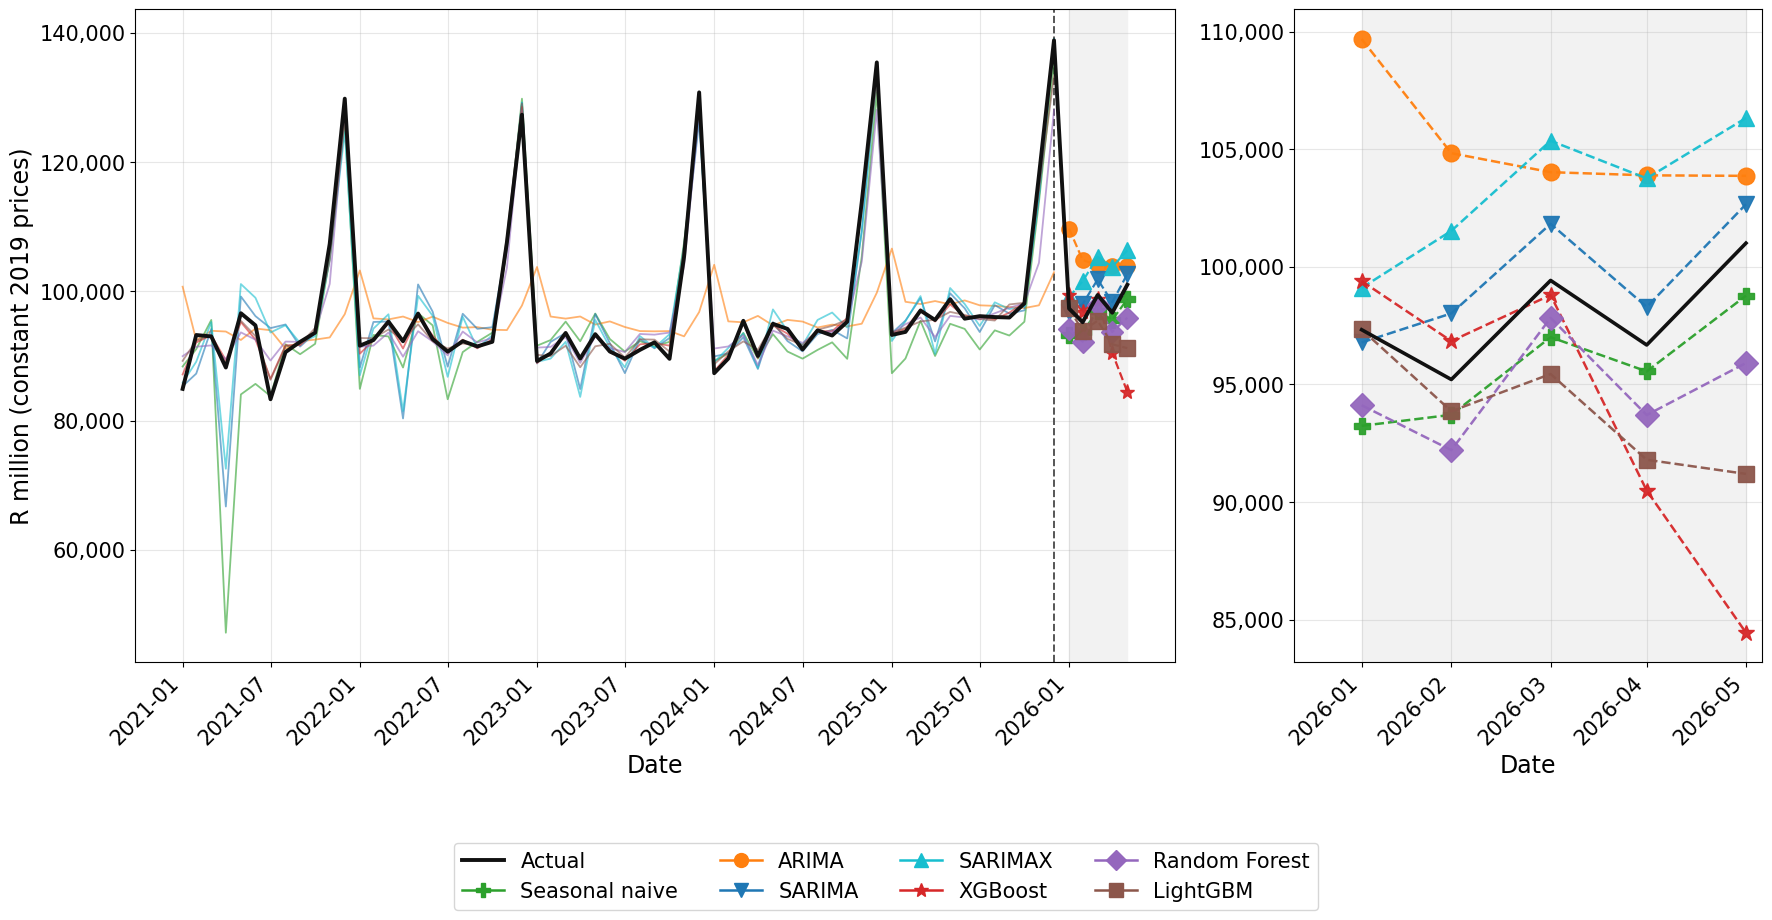

Saved -> plot_in_sample_Forecast.png


In [17]:
# ─── SECTION 4h : PLOT — in-sample fit + holdout forecasts (enlarged, clean legend) ─
print("\n" + "=" * 65); print("SECTION 4h — In-sample fit and holdout-forecast plot"); print("=" * 65)
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

def insample_fitted_tree(model_factory, frame, feature_cols, origin_position):
    """One-step in-sample fitted values from the h=1 tree model."""
    feature_matrix = frame[feature_cols]; target_values = frame[TARGET_COL].values; n_rows = len(frame)
    train_positions = [i for i in range(n_rows) if i + 1 <= origin_position
                       and feature_matrix.iloc[i].notna().all() and not np.isnan(target_values[i + 1])]
    model = model_factory(); model.fit(feature_matrix.iloc[train_positions].values,
                                       target_values[[i + 1 for i in train_positions]])
    fitted = pd.Series(index=frame.index, dtype=float)
    predict_positions = [i for i in range(n_rows - 1) if feature_matrix.iloc[i].notna().all()]
    predictions = model.predict(feature_matrix.iloc[predict_positions].values)
    for position, prediction in zip(predict_positions, predictions):
        fitted.iloc[position + 1] = prediction
    return fitted

# Pure SARIMA (seasonal, no exog) on the training window: in-sample fit + holdout forecast.
_pure_model = ARIMA(train_data[TARGET_COL].astype(float), order=(1, 1, 1),
                    seasonal_order=(0, 1, 1, 12)).fit()
_pure_raw = _pure_model.forecast(max(HORIZONS))
pure_sarima_forecast = {h: float(_pure_raw.iloc[h - 1]) for h in HORIZONS}

# model -> (in-sample fitted series, holdout forecast dict, colour, marker)
plot_models = [
    ("Seasonal naive", target_series.shift(12), seasonal_naive_forecast, "#2ca02c", "P"),
    ("ARIMA",          arima_model.fittedvalues, arima_forecast,          "#ff7f0e", "o"),
    ("SARIMA",         _pure_model.fittedvalues, pure_sarima_forecast,    "#1f77b4", "v"),
    ("SARIMAX",        sarimax_model.fittedvalues, sarimax_forecast,      "#17becf", "^"),
    ("XGBoost",        insample_fitted_tree(make_xgboost, data, FEATURE_COLS, origin_pos), xgboost_forecast, "#d62728", "*"),
    ("Random Forest",  insample_fitted_tree(make_random_forest, data, FEATURE_COLS, origin_pos), random_forest_forecast, "#9467bd", "D"),
    ("LightGBM",       insample_fitted_tree(make_lightgbm, data, FEATURE_COLS, origin_pos), lightgbm_forecast, "#8c564b", "s"),
]
from matplotlib.ticker import FuncFormatter
_thousands = FuncFormatter(lambda v, p: f"{v:,.0f}")

holdout_dates = [data.index[origin_pos + h] for h in HORIZONS]
plot_start = "2021-01-01"
plt.rcParams.update({"font.size": 16})
fig, (ax, axz) = plt.subplots(1, 2, figsize=(18, 8.5), gridspec_kw={"width_ratios": [3.0, 1.35]})

actual_window = target_series.loc[plot_start:]
ax.plot(actual_window.index, actual_window.values, color="#111", linewidth=2.8, zorder=10)
for name, fitted, fc, colour, marker in plot_models:
    w = fitted.loc[plot_start:LAST_TRAIN_DATE]
    ax.plot(w.index, w.values, color=colour, linewidth=1.3, alpha=0.6, zorder=3)
    ax.plot(holdout_dates, [fc[h] for h in HORIZONS], linestyle="--", marker=marker,
            color=colour, markersize=11, linewidth=1.6, alpha=0.95, zorder=6)
ax.axvspan(holdout_dates[0], holdout_dates[-1], color="#f2f2f2", zorder=0)
ax.axvline(data.index[origin_pos], color="#555", linestyle="--", linewidth=1.4)
ax.set_xlabel("Date", fontsize=17)
ax.set_ylabel("R million (constant 2019 prices)", fontsize=17)
ax.yaxis.set_major_formatter(_thousands)
ax.set_xticks(actual_window.index[::6])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.tick_params(labelsize=15)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right"); ax.grid(True, alpha=0.3)

zoom_actual = target_series.loc["2026-01-01":]
axz.plot(zoom_actual.index, zoom_actual.values, color="#111", linewidth=2.6, zorder=10)
for name, fitted, fc, colour, marker in plot_models:
    axz.plot(holdout_dates, [fc[h] for h in HORIZONS], linestyle="--", marker=marker,
             color=colour, markersize=12, linewidth=1.8, alpha=0.95, zorder=6)
axz.axvspan(holdout_dates[0], holdout_dates[-1], color="#f2f2f2", zorder=0)
axz.set_xlim(pd.Timestamp("2026-01-10"), pd.Timestamp("2026-06-05"))
axz.set_xlabel("Date", fontsize=17)
axz.yaxis.set_major_formatter(_thousands)
axz.set_xticks(zoom_actual.index)
axz.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axz.tick_params(labelsize=15)
plt.setp(axz.get_xticklabels(), rotation=45, ha="right"); axz.grid(True, alpha=0.3)

handles = [Line2D([0], [0], color="#111", lw=2.8, label="Actual")]
for name, fitted, fc, colour, marker in plot_models:
    handles.append(Line2D([0], [0], color=colour, lw=1.8, marker=marker, markersize=10, label=name))
fig.legend(handles=handles, fontsize=15, loc="lower center", ncol=4, frameon=True,
           bbox_to_anchor=(0.5, -0.10))
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("plot_in_sample_Forecast.png", dpi=200, bbox_inches="tight"); plt.show()
print("Saved -> plot_in_sample_Forecast.png")


## SECTION 5 — Rolling-origin walk-forward validation

Where **all statistical inference** lives. Origins advance monthly from
`FIRST_ORIGIN_DATE`; at **every origin** the winsorisation bounds and the SARIMAX exog
screen use train-only data, **ARIMA and SARIMAX are re-estimated from scratch**, and the
tree models use the direct multi-step raw-level target (TREE_TARGET='level'). **This is the slow cell**
(~20–40 min on Colab; set `FIRST_ORIGIN_DATE='2005-01-31'` for a faster pass).

In [18]:
# ─── SECTION 5a : Walk-forward run (ALL models re-estimated per origin) ──────
print("=" * 65); print("SECTION 5a — Rolling-origin walk-forward"); print("=" * 65)

last_train_pos   = data.index.get_loc(pd.Timestamp(LAST_TRAIN_DATE))
first_origin_pos = data.index.get_loc(pd.Timestamp(FIRST_ORIGIN_DATE))
last_origin_pos  = last_train_pos - max(HORIZONS)
origin_positions = list(range(first_origin_pos, last_origin_pos + 1))
print(f"{len(origin_positions)} origins: {data.index[first_origin_pos].date()} -> "
      f"{data.index[last_origin_pos].date()}\n")


def select_exog(train_slice):
    """Origin-relative SARIMAX exog screen (train-only): |r|>=0.15 and CV<=2.0."""
    retained = []
    for candidate in ["cpi_signal", "electricity", "exchange_rate", "cci_level"]:
        candidate_series = train_slice[candidate]
        if candidate_series.notna().sum() < 60:
            continue
        correlation = np.corrcoef(candidate_series.fillna(candidate_series.mean()), train_slice[TARGET_COL])[0, 1]
        coef_var = abs(candidate_series.std() / candidate_series.mean()) if candidate_series.mean() != 0 else np.inf
        if abs(correlation) >= 0.15 and coef_var <= 2.0:
            retained.append(candidate)
    return retained


def fit_econometric(frame, origin_position):
    """Refit ARIMA and SARIMAX from scratch at this origin."""
    train_slice  = frame.iloc[:origin_position + 1]
    train_target = train_slice[TARGET_COL].astype(float)
    forecasts = {"ARIMA": {}, "SARIMAX": {}, "Pure SARIMA": {}}
    try:
        arima_fc = ARIMA(train_target, order=(1, 1, 1)).fit().forecast(max(HORIZONS))
        for horizon in HORIZONS:
            forecasts["ARIMA"][horizon] = float(arima_fc.iloc[horizon - 1])
    except Exception:
        pass
    retained = select_exog(train_slice)
    try:
        if retained:
            exog_train = train_slice[retained].ffill().bfill()
            exog_projection = {}
            for candidate in retained:
                recent_tail = exog_train[candidate].iloc[-12:].values
                trend_coef  = np.polyfit(np.arange(12), recent_tail, 1)
                projected   = np.polyval(trend_coef, np.arange(12, 12 + max(HORIZONS)))
                change_cap  = 3 * np.std(np.diff(recent_tail))
                exog_projection[candidate] = np.clip(projected, recent_tail[-1] - change_cap,
                                                     recent_tail[-1] + change_cap)
            sarimax_fc = (ARIMA(train_target, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12),
                                exog=exog_train.values).fit()
                          .forecast(max(HORIZONS),
                                    exog=np.column_stack([exog_projection[c] for c in retained])))
        else:
            sarimax_fc = ARIMA(train_target, order=(1, 1, 1),
                               seasonal_order=(0, 1, 1, 12)).fit().forecast(max(HORIZONS))
        for horizon in HORIZONS:
            forecasts["SARIMAX"][horizon] = float(sarimax_fc.iloc[horizon - 1])
    except Exception:
        pass
    # Pure SARIMA (seasonal model with NO exogenous regressors), re-fit at this origin.
    try:
        pure_fc = ARIMA(train_target, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit().forecast(max(HORIZONS))
        for horizon in HORIZONS:
            forecasts["Pure SARIMA"][horizon] = float(pure_fc.iloc[horizon - 1])
    except Exception:
        pass
    return forecasts


walk_forward_records = []
start_time = time.time()
for step, origin_position in enumerate(origin_positions):
    frame = data.copy()
    if USE_WINSOR:
        winsor_lo, winsor_hi = frame[TARGET_COL].pct_change().iloc[:origin_position + 1].quantile([0.01, 0.99])
        frame["retail_growth_winsor"] = frame["retail_growth"].clip(winsor_lo, winsor_hi)

    origin_actuals = {horizon: float(target_series.iloc[origin_position + horizon]) for horizon in HORIZONS}
    forecasts_this_origin = {
        "Naive":         {horizon: float(target_series.iloc[origin_position]) for horizon in HORIZONS},
        "SeasonalNaive": {horizon: float(target_series.iloc[origin_position + horizon - 12]) for horizon in HORIZONS},
        **fit_econometric(frame, origin_position),
        "XGBoost":       fit_direct_multistep(make_xgboost, frame, FEATURE_COLS, origin_position),
        "RandomForest":  fit_direct_multistep(make_random_forest, frame, FEATURE_COLS, origin_position),
        "LightGBM":      fit_direct_multistep(make_lightgbm, frame, FEATURE_COLS, origin_position),
    }
    for model_name, forecast_by_horizon in forecasts_this_origin.items():
        for horizon in HORIZONS:
            if horizon in forecast_by_horizon:
                actual    = origin_actuals[horizon]
                predicted = forecast_by_horizon[horizon]
                walk_forward_records.append((data.index[origin_position].date(), model_name, horizon,
                                             actual, predicted,
                                             abs((actual - predicted) / actual) * 100,
                                             (actual - predicted) ** 2))
    if step % 25 == 0:
        elapsed = time.time() - start_time
        eta = elapsed / (step + 1) * (len(origin_positions) - step - 1)
        print(f"  {step}/{len(origin_positions)}  {elapsed:.0f}s  eta {eta:.0f}s", flush=True)

walk_forward = pd.DataFrame(walk_forward_records,
                            columns=["origin", "model", "horizon", "actual", "predicted", "ape", "squared_error"])
walk_forward.to_csv("wf_results.csv", index=False)
print(f"\nwalk-forward done: {walk_forward.shape} in {time.time()-start_time:.0f}s  (saved wf_results.csv)")

SECTION 5a — Rolling-origin walk-forward
307 origins: 2000-01-31 -> 2025-07-31



/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_date

  0/307  7s  eta 2199s


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_date

  25/307  193s  eta 2083s


...

  275/307  2095s  eta 235s


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_date

  300/307  2340s  eta 47s


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_date


walk-forward done: (12280, 7) in 2403s  (saved wf_results.csv)


In [19]:
# ─── SECTION 5b : Accuracy — MAPE (mean) vs MdAPE (median) ───────────────────
print("\n" + "=" * 65); print("SECTION 5b — MAPE vs MdAPE by model x horizon"); print("=" * 65)
MODEL_ORDER = ["Naive", "SeasonalNaive", "ARIMA", "SARIMAX", "Pure SARIMA", "RandomForest", "XGBoost", "LightGBM"]
accuracy_by_model_horizon = (walk_forward.groupby(["model", "horizon"])["ape"]
                             .agg(MAPE="mean", MdAPE="median").reset_index())
print("\nMdAPE (median APE — typical accuracy):")
print(accuracy_by_model_horizon.pivot(index="model", columns="horizon", values="MdAPE")
      .reindex(MODEL_ORDER).round(2).to_string())
print("\nMAPE (mean APE — inflated by rare shock months, e.g. Apr/May 2020):")
print(accuracy_by_model_horizon.pivot(index="model", columns="horizon", values="MAPE")
      .reindex(MODEL_ORDER).round(2).to_string())


SECTION 5b — MAPE vs MdAPE by model x horizon

MdAPE (median APE — typical accuracy):
horizon           1     2     3     4     5
model                                      
Naive          3.15  4.37  5.13  5.47  4.89
SeasonalNaive  3.25  3.22  3.22  3.22  3.22
ARIMA          3.44  3.71  3.77  3.70  3.81
SARIMAX        1.53  1.78  1.93  2.26  2.30
Pure SARIMA    1.48  1.64  1.85  2.10  2.02
RandomForest   3.38  3.82  4.03  3.33  3.11
XGBoost        2.31  3.23  3.42  3.47  3.37
LightGBM       3.59  3.33  3.04  3.50  3.65

MAPE (mean APE — inflated by rare shock months, e.g. Apr/May 2020):
horizon           1      2      3      4      5
model                                          
Naive          8.90  10.80  10.64  11.10  10.63
SeasonalNaive  4.57   4.57   4.57   4.57   4.57
ARIMA          6.99   6.94   6.70   6.77   6.85
SARIMAX        2.66   2.92   3.12   3.39   3.55
Pure SARIMA    2.59   2.82   3.04   3.28   3.42
RandomForest   5.00   6.05   6.55   5.84   5.78
XGBoost        3.48 


SECTION 5b-plot — Model comparison across horizons


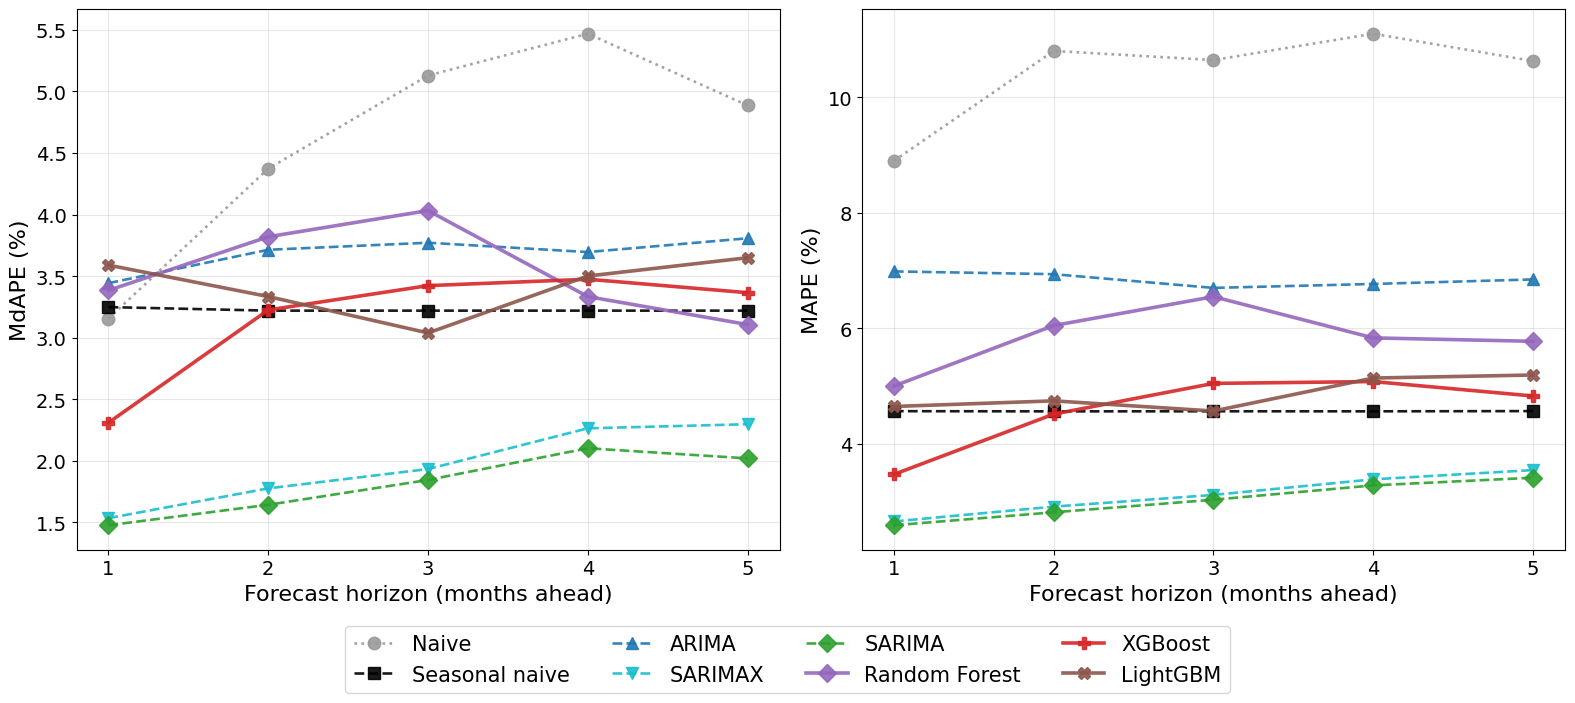

Saved -> fig2_model_comparison.png

Average accuracy across h=1..5 (sorted by MdAPE):
               avg_MdAPE  avg_MAPE
model                             
Pure SARIMA         1.82      3.03
SARIMAX             1.96      3.13
XGBoost             3.16      4.59
SeasonalNaive       3.23      4.57
LightGBM            3.42      4.86
RandomForest        3.54      5.84
ARIMA               3.69      6.85
Naive               4.60     10.41


In [20]:
# ─── SECTION 5b-plot : MODEL COMPARISON GRAPH (accuracy by horizon) ──────────
print("\n" + "=" * 65); print("SECTION 5b-plot — Model comparison across horizons"); print("=" * 65)

# Two panels: MdAPE (typical) and MAPE (mean) by horizon. Tree/ML models drawn as
# solid lines, econometric + naive benchmarks as dashed, so the ML-vs-benchmark
# comparison is visible at a glance.
model_styles = {
    "Naive":         ("#999999", ":",  "o"),
    "SeasonalNaive": ("#000000", "--", "s"),
    "ARIMA":         ("#1f77b4", "--", "^"),
    "SARIMAX":       ("#17becf", "--", "v"),
    "Pure SARIMA":   ("#2ca02c", "--", "D"),
    "RandomForest":  ("#9467bd", "-",  "D"),
    "XGBoost":       ("#d62728", "-",  "P"),
    "LightGBM":      ("#8c564b", "-",  "X"),
}
accuracy_pivot_mdape = accuracy_by_model_horizon.pivot(index="model", columns="horizon", values="MdAPE")
accuracy_pivot_mape  = accuracy_by_model_horizon.pivot(index="model", columns="horizon", values="MAPE")

plt.rcParams.update({"font.size": 15})
_display = {"SeasonalNaive": "Seasonal naive", "RandomForest": "Random Forest", "Pure SARIMA": "SARIMA"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6.4), sharex=True)
for metric_label, pivot, axis in [("MdAPE (%)", accuracy_pivot_mdape, axes[0]),
                                  ("MAPE (%)",  accuracy_pivot_mape,  axes[1])]:
    for model_name in [m for m in model_styles if m in pivot.index]:
        colour, line_style, marker = model_styles[model_name]
        axis.plot(HORIZONS, pivot.loc[model_name, HORIZONS].values, marker=marker,
                  linestyle=line_style, color=colour, linewidth=2.6 if line_style == "-" else 1.9,
                  markersize=9, label=_display.get(model_name, model_name), alpha=0.9)
    axis.set_xlabel("Forecast horizon (months ahead)", fontsize=16); axis.set_ylabel(metric_label, fontsize=16)
    axis.set_xticks(HORIZONS); axis.tick_params(labelsize=14); axis.grid(True, alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=True, bbox_to_anchor=(0.5, -0.12), fontsize=15)
plt.tight_layout(); plt.savefig("fig2_model_comparison.png", dpi=200, bbox_inches="tight"); plt.show()
print("Saved -> fig2_model_comparison.png")

# Companion bar chart: average accuracy across horizons per model (single summary view)
avg_mdape = accuracy_pivot_mdape[HORIZONS].mean(axis=1).reindex(MODEL_ORDER)
avg_mape  = accuracy_pivot_mape[HORIZONS].mean(axis=1).reindex(MODEL_ORDER)
summary_ranks = pd.DataFrame({"avg_MdAPE": avg_mdape.round(2), "avg_MAPE": avg_mape.round(2)}).sort_values("avg_MdAPE")
print("\nAverage accuracy across h=1..5 (sorted by MdAPE):")
print(summary_ranks.to_string())

In [21]:
# ─── SECTION 5c : Diebold-Mariano tests (HLN-modified) on walk-forward ───────
print("\n" + "=" * 65); print("SECTION 5c — Diebold-Mariano (vs SeasonalNaive and vs SARIMAX)"); print("=" * 65)

def diebold_mariano(loss_a, loss_b, horizon):
    """Harvey-Leybourne-Newbold modified DM statistic; negative => loss_a < loss_b (a better)."""
    loss_diff = np.asarray(loss_a, float) - np.asarray(loss_b, float)
    loss_diff = loss_diff[~np.isnan(loss_diff)]
    n_obs = len(loss_diff)
    if n_obs < 8:
        return np.nan, np.nan
    gamma0 = np.var(loss_diff, ddof=0)
    gamma_sum = sum(2 * np.cov(loss_diff[lag:], loss_diff[:-lag])[0, 1]
                    for lag in range(1, horizon) if lag < n_obs)
    long_run_var = (gamma0 + gamma_sum) / n_obs
    if long_run_var <= 0:
        return np.nan, np.nan
    dm_stat = loss_diff.mean() / np.sqrt(long_run_var)
    dm_stat *= np.sqrt((n_obs + 1 - 2 * horizon + horizon * (horizon - 1) / n_obs) / n_obs)
    return float(dm_stat), float(2 * (1 - stats.t.cdf(abs(dm_stat), df=n_obs - 1)))

def loss_of(model_name, horizon):
    return (walk_forward[(walk_forward.model == model_name) & (walk_forward.horizon == horizon)]
            .set_index("origin")["squared_error"])

def dm_table(benchmark_name, model_names):
    table_rows = []
    for model_name in model_names:
        for horizon in HORIZONS:
            loss_model = loss_of(model_name, horizon)
            loss_bench = loss_of(benchmark_name, horizon)
            common_index = loss_model.index.intersection(loss_bench.index)
            dm_stat, p_value = diebold_mariano(loss_model.loc[common_index].values,
                                               loss_bench.loc[common_index].values, horizon)
            table_rows.append((model_name, horizon,
                               round(dm_stat, 2) if dm_stat == dm_stat else np.nan,
                               round(p_value, 4) if p_value == p_value else np.nan))
    return pd.DataFrame(table_rows, columns=["model", "horizon", f"DM_vs_{benchmark_name}", "p"])

print("\nvs SeasonalNaive (negative DM & p<0.05 => model beats the benchmark):")
print(dm_table("SeasonalNaive", ["Naive", "ARIMA", "SARIMAX", "Pure SARIMA", "RandomForest", "XGBoost", "LightGBM"]).to_string(index=False))
print("\nvs SARIMAX (ML vs econometric, both re-estimated per origin):")
print(dm_table("SARIMAX", ["Naive", "ARIMA", "Pure SARIMA", "RandomForest", "XGBoost", "LightGBM"]).to_string(index=False))


SECTION 5c — Diebold-Mariano (vs SeasonalNaive and vs SARIMAX)

vs SeasonalNaive (negative DM & p<0.05 => model beats the benchmark):
       model  horizon  DM_vs_SeasonalNaive      p
       Naive        1                 6.28 0.0000
       Naive        2                 7.16 0.0000
       Naive        3                 9.21 0.0000
       Naive        4                13.04 0.0000
       Naive        5                15.72 0.0000
       ARIMA        1                 5.12 0.0000
       ARIMA        2                 4.74 0.0000
       ARIMA        3                 4.97 0.0000
       ARIMA        4                 5.76 0.0000
       ARIMA        5                 6.91 0.0000
     SARIMAX        1                -3.23 0.0014
     SARIMAX        2                -1.87 0.0622
     SARIMAX        3                -1.22 0.2231
     SARIMAX        4                -0.42 0.6734
     SARIMAX        5                 0.02 0.9878
 Pure SARIMA        1                -3.80 0.0002
 Pure SARIMA   

## Section 5c-ii — Multiple-comparison control (Benjamini–Hochberg)

The Diebold–Mariano tests form a family (each model vs Seasonal Naive, and each model vs SARIMAX). This cell controls that family's p-values at a 5% false-discovery rate with the Benjamini–Hochberg procedure. It uses `walk_forward`, `diebold_mariano` and `loss_of` from Section 5c, so run Sections 5a and 5c first; PureSARIMA is included because it is now part of the Section 5a walk-forward.

In [22]:
# ─── SECTION 5c-ii : Benjamini-Hochberg FDR control across the full DM family ─
from statsmodels.stats.multitest import multipletests

# Every pairwise DM test reported in the paper: each model vs Seasonal Naive,
# and each non-benchmark model vs SARIMAX.
bh_pairs = ([(m, "SeasonalNaive") for m in ["Naive", "ARIMA", "SARIMAX", "Pure SARIMA",
                                            "RandomForest", "XGBoost", "LightGBM"]]
          + [(m, "SARIMAX")       for m in ["Naive", "ARIMA", "Pure SARIMA",
                                            "RandomForest", "XGBoost", "LightGBM"]])

bh_rows = []
for model_name, benchmark_name in bh_pairs:
    for horizon in HORIZONS:
        loss_model = loss_of(model_name, horizon)
        loss_bench = loss_of(benchmark_name, horizon)
        common_index = loss_model.index.intersection(loss_bench.index)
        if len(common_index) < 8:
            continue
        dm_stat, p_value = diebold_mariano(loss_model.loc[common_index].values,
                                           loss_bench.loc[common_index].values, horizon)
        bh_rows.append({"model": model_name, "benchmark": benchmark_name,
                        "horizon": horizon, "DM": dm_stat, "p_raw": p_value})

bh_table = pd.DataFrame(bh_rows).dropna(subset=["p_raw"]).reset_index(drop=True)
reject, p_bh, _, _ = multipletests(bh_table["p_raw"], alpha=0.05, method="fdr_bh")
bh_table["p_BH"] = p_bh
bh_table["significant_5pct"] = reject
bh_table.to_csv("dm_benjamini_hochberg.csv", index=False)

print(f"{len(bh_table)} pairwise Diebold-Mariano tests; "
      f"{int(reject.sum())} remain significant after Benjamini-Hochberg at 5%.\n")
print(bh_table.sort_values("p_raw").round(4).to_string(index=False))
print("\n(saved dm_benjamini_hochberg.csv)")

65 pairwise Diebold-Mariano tests; 37 remain significant after Benjamini-Hochberg at 5%.

       model     benchmark  horizon      DM  p_raw   p_BH  significant_5pct
       Naive SeasonalNaive        4 13.0388 0.0000 0.0000              True
       Naive SeasonalNaive        3  9.2137 0.0000 0.0000              True
       Naive SeasonalNaive        5 15.7247 0.0000 0.0000              True
       Naive       SARIMAX        4 14.2610 0.0000 0.0000              True
       Naive       SARIMAX        5 26.6522 0.0000 0.0000              True
       Naive       SARIMAX        3  9.4947 0.0000 0.0000              True
       Naive       SARIMAX        2  7.5817 0.0000 0.0000              True
       Naive SeasonalNaive        2  7.1563 0.0000 0.0000              True
       ARIMA SeasonalNaive        5  6.9052 0.0000 0.0000              True
       Naive       SARIMAX        1  6.8469 0.0000 0.0000              True
       ARIMA       SARIMAX        5  6.7804 0.0000 0.0000              Tru

In [23]:
# ─── SECTION 5d : Ablation on the ROLLING-ORIGIN results (best ML model) ─────
print("\n" + "=" * 65); print("SECTION 5d — Leave-one-group-out ablation (walk-forward MdAPE)"); print("=" * 65)
CONFORMAL_MODEL = globals().get("CONFORMAL_MODEL", "auto")
tree_model_factories = globals().get("tree_model_factories",
    {"XGBoost": make_xgboost, "RandomForest": make_random_forest, "LightGBM": make_lightgbm})
if CONFORMAL_MODEL == "auto":
    _tree_wf = walk_forward[walk_forward.model.isin(["RandomForest", "XGBoost", "LightGBM"])]
    ablation_model = (_tree_wf.groupby(["model", "horizon"])["ape"].median()
                      .groupby("model").mean().idxmin())
else:
    ablation_model = CONFORMAL_MODEL
ablation_factory = tree_model_factories[ablation_model]
print(f"Ablating the best tree: {ablation_model}\n")
FEATURE_GROUPS = {
    "calendar": ["month", "quarter", "is_december", "is_november", "is_april"],
    "lags":     ["retail_lag_1", "retail_lag_3", "retail_lag_6", "retail_lag_12"],
    "rolling":  ["retail_roll_3", "retail_roll_6", "retail_roll_std6"],
    "macro":    ["cpi_signal", "electricity", "exchange_rate", "cci_level"],
    "growth":   ["retail_growth_winsor"],
    "cpi_only": ["cpi_signal"],
}

def walk_forward_median(feature_cols):
    """Median APE per horizon from a walk-forward of the selected tree with the given features."""
    errors_by_horizon = {horizon: [] for horizon in HORIZONS}
    for origin_position in origin_positions:
        frame = data.copy()
        if USE_WINSOR:
            winsor_lo, winsor_hi = frame[TARGET_COL].pct_change().iloc[:origin_position + 1].quantile([0.01, 0.99])
            frame["retail_growth_winsor"] = frame["retail_growth"].clip(winsor_lo, winsor_hi)
        forecast_by_horizon = fit_direct_multistep(ablation_factory, frame, feature_cols, origin_position)
        for horizon in HORIZONS:
            actual = float(target_series.iloc[origin_position + horizon])
            errors_by_horizon[horizon].append(abs((actual - forecast_by_horizon[horizon]) / actual) * 100)
    return {horizon: float(np.median(errors_by_horizon[horizon])) for horizon in HORIZONS}

baseline_median = walk_forward_median(FEATURE_COLS)
ablation_rows = [("full", *[round(baseline_median[h], 3) for h in HORIZONS], 0.0)]
for group_name, group_cols in FEATURE_GROUPS.items():
    reduced_median = walk_forward_median([f for f in FEATURE_COLS if f not in group_cols])
    avg_delta = float(np.mean([reduced_median[h] - baseline_median[h] for h in HORIZONS]))
    ablation_rows.append((f"-{group_name}", *[round(reduced_median[h], 3) for h in HORIZONS], round(avg_delta, 3)))

ablation_table = pd.DataFrame(ablation_rows,
                              columns=["config"] + [f"MdAPE_h{h}" for h in HORIZONS] + ["avg_delta"])
ablation_table.to_csv("ablation_results.csv", index=False)
print(ablation_table.to_string(index=False))
print(f"\nAblated model: {ablation_model}.  +avg_delta => removing the group HURTS accuracy (useful); ~0/negative => redundant.")


SECTION 5d — Leave-one-group-out ablation (walk-forward MdAPE)
Ablating the best tree: XGBoost

   config  MdAPE_h1  MdAPE_h2  MdAPE_h3  MdAPE_h4  MdAPE_h5  avg_delta
     full     2.310     3.225     3.423     3.475     3.365      0.000
-calendar     3.962     4.031     4.808     4.589     5.098      1.338
    -lags     2.323     3.112     3.365     3.735     3.307      0.009
 -rolling     2.294     2.814     2.901     3.580     3.433     -0.155
   -macro     2.438     2.789     2.809     2.913     3.241     -0.321
  -growth     2.350     2.977     3.159     3.261     3.337     -0.143
-cpi_only     2.250     3.307     3.346     3.317     3.386     -0.038

Ablated model: XGBoost.  +avg_delta => removing the group HURTS accuracy (useful); ~0/negative => redundant.


In [24]:
# ─── SECTION 5d-ii : SARIMAX exogenous-variable ablation (rolling-origin) ────
# Complements the tree ablation: tests whether the exogenous regressors help the
# BEST OVERALL forecaster (SARIMAX). Refits SARIMAX on every rolling origin with the
# full screened exog set, with no exog, and dropping each exog in turn. Slow
# (one SARIMAX refit per origin per configuration).
print("\n" + "=" * 65); print("SECTION 5d-ii — SARIMAX exogenous-variable ablation"); print("=" * 65)

# self-contained fallbacks so this can run as a standalone tail cell after Section 5a
if "origin_positions" not in globals():
    last_train_pos   = data.index.get_loc(pd.Timestamp(LAST_TRAIN_DATE))
    first_origin_pos = data.index.get_loc(pd.Timestamp(FIRST_ORIGIN_DATE))
    origin_positions = list(range(first_origin_pos, last_train_pos - max(HORIZONS) + 1))
if "select_exog" not in globals():
    def select_exog(train_slice):
        retained = []
        for candidate in ["cpi_signal", "electricity", "exchange_rate", "cci_level"]:
            series = train_slice[candidate]
            if series.notna().sum() < 60:
                continue
            correlation = np.corrcoef(series.fillna(series.mean()), train_slice[TARGET_COL])[0, 1]
            coef_var = abs(series.std() / series.mean()) if series.mean() != 0 else np.inf
            if abs(correlation) >= 0.15 and coef_var <= 2.0:
                retained.append(candidate)
        return retained

def sarimax_forecast_with_exog(train_target, exog_names, train_slice):
    """Refit SARIMAX(1,1,1)(0,1,1,12) at one origin using the given exog names (train-only projection)."""
    if exog_names:
        exog_train = train_slice[exog_names].ffill().bfill()
        projection = {}
        for name in exog_names:
            recent_tail = exog_train[name].iloc[-12:].values
            trend_coef  = np.polyfit(np.arange(12), recent_tail, 1)
            projected   = np.polyval(trend_coef, np.arange(12, 12 + max(HORIZONS)))
            change_cap  = 3 * np.std(np.diff(recent_tail))
            projection[name] = np.clip(projected, recent_tail[-1] - change_cap, recent_tail[-1] + change_cap)
        exog_future = np.column_stack([projection[n] for n in exog_names])
        fitted = ARIMA(train_target, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12),
                       exog=exog_train.values).fit()
        return fitted.forecast(max(HORIZONS), exog=exog_future)
    fitted = ARIMA(train_target, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit()
    return fitted.forecast(max(HORIZONS))

def sarimax_walk_forward_median(exog_rule):
    """exog_rule: 'screen' (screened set), 'none', or ('drop', name)."""
    errors_by_horizon = {horizon: [] for horizon in HORIZONS}
    for origin_position in origin_positions:
        train_slice  = data.iloc[:origin_position + 1]
        train_target = train_slice[TARGET_COL].astype(float)
        screened = select_exog(train_slice)
        if exog_rule == "screen":
            exog_names = screened
        elif exog_rule == "none":
            exog_names = []
        else:  # ("drop", name)
            exog_names = [c for c in screened if c != exog_rule[1]]
        try:
            forecast = sarimax_forecast_with_exog(train_target, exog_names, train_slice)
            for horizon in HORIZONS:
                actual = float(target_series.iloc[origin_position + horizon])
                errors_by_horizon[horizon].append(abs((actual - float(forecast.iloc[horizon - 1])) / actual) * 100)
        except Exception:
            pass
    return {horizon: float(np.median(errors_by_horizon[horizon])) for horizon in HORIZONS}

sarimax_configs = [
    ("SARIMAX (full screened exog)", "screen"),
    ("- no exogenous (pure SARIMA)", "none"),
    ("- drop CPI inflation",         ("drop", "cpi_signal")),
    ("- drop electricity",           ("drop", "electricity")),
    ("- drop exchange rate",         ("drop", "exchange_rate")),
]
sarimax_baseline = None
sarimax_ablation_rows = []
for label, rule in sarimax_configs:
    median_by_horizon = sarimax_walk_forward_median(rule)
    avg_median = float(np.mean([median_by_horizon[h] for h in HORIZONS]))
    if rule == "screen":
        sarimax_baseline = avg_median
        delta = 0.0
    else:
        delta = avg_median - sarimax_baseline
    sarimax_ablation_rows.append({"config": label,
                                  **{f"MdAPE_h{h}": round(median_by_horizon[h], 3) for h in HORIZONS},
                                  "avg_MdAPE": round(avg_median, 3), "avg_delta": round(delta, 3)})
    print(f"  {label:32s} avg MdAPE={avg_median:5.2f}  delta={delta:+.3f}")

sarimax_ablation_table = pd.DataFrame(sarimax_ablation_rows)
sarimax_ablation_table.to_csv("sarimax_exog_ablation.csv", index=False)
print("\n" + sarimax_ablation_table.to_string(index=False))
print("\n+avg_delta => removing the exog HURTS SARIMAX; ~0/negative => the exog is redundant for SARIMAX.")
print("(saved sarimax_exog_ablation.csv)")


SECTION 5d-ii — SARIMAX exogenous-variable ablation


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_date

  SARIMAX (full screened exog)     avg MdAPE= 1.96  delta=+0.000


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_date

  - no exogenous (pure SARIMA)     avg MdAPE= 1.82  delta=-0.144


...

  - drop CPI inflation             avg MdAPE= 1.97  delta=+0.010


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_date

  - drop electricity               avg MdAPE= 1.91  delta=-0.053


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_date

  - drop exchange rate             avg MdAPE= 2.08  delta=+0.116

                      config  MdAPE_h1  MdAPE_h2  MdAPE_h3  MdAPE_h4  MdAPE_h5  avg_MdAPE  avg_delta
SARIMAX (full screened exog)     1.535     1.777     1.934     2.264     2.297      1.961      0.000
- no exogenous (pure SARIMA)     1.477     1.643     1.845     2.102     2.020      1.818     -0.144
        - drop CPI inflation     1.599     1.731     1.985     2.230     2.313      1.972      0.010
          - drop electricity     1.639     1.763     1.896     2.061     2.181      1.908     -0.053
        - drop exchange rate     1.625     1.813     2.138     2.355     2.455      2.077      0.116

+avg_delta => removing the exog HURTS SARIMAX; ~0/negative => the exog is redundant for SARIMAX.
(saved sarimax_exog_ablation.csv)



SECTION 5e — Split-conformal prediction intervals
Walk-forward ranking -> best overall: Pure SARIMA | best tree: XGBoost
Primary conformal model (best overall): Pure SARIMA



/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


Pure SARIMA on the Jan-May 2026 holdout (Table 1 row):
  SARIMA (no exog)           RMSE=  1,966.4  MAE=  1,805.8  MAPE=  1.85%  MdAPE=  1.67%  sMAPE=  1.83%  R2= 0.0810

>>> Primary split-conformal — best overall model: Pure SARIMA
Coverage across ALL rolling origins (per horizon, pooled, N):
nominal  cover_h1  cover_h2  cover_h3  cover_h4  cover_h5  pooled_%  n_forecasts
    80%      76.7      77.0      75.4      76.4      76.0      76.3         1405
    95%      89.4      90.4      89.7      89.6      88.5      89.5         1405

Average interval width (% of point forecast) — the paper's width table:
 horizon  avg_width80_pct  avg_width95_pct
       1              6.3             14.8
       2              7.8             15.6
       3              8.5             16.2
       4              9.2             17.6
       5              9.7             18.0

Jan-May 2026 holdout intervals (Pure SARIMA):
   month  point  actual  lower80  upper80  in80  lower95  upper95  in95  width80_pct

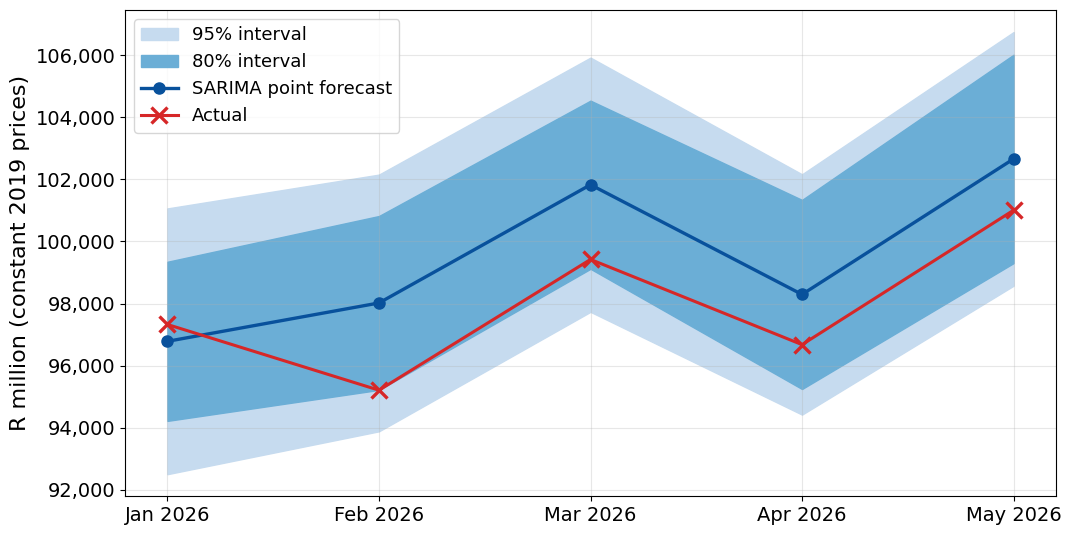

Saved -> plot_conformal_bands.png


In [25]:
# ─── SECTION 5e : Conformal — rolling-origin coverage + 2026 holdout intervals ─
# Split-conformal intervals are attached to the BEST OVERALL model across the
# walk-forward. The SAME procedure is also applied to the BEST TREE for the
# comparison the paper reports. If the best overall model IS the best tree, the
# two coincide and only one set is produced (we do not run conformal twice on one
# model).
print("\n" + "=" * 65); print("SECTION 5e — Split-conformal prediction intervals"); print("=" * 65)
CALIBRATION_WINDOW = 24
TREES = ["RandomForest", "XGBoost", "LightGBM"]

# Rank models by mean-over-horizons median APE on the walk-forward.
_mean_mdape = (walk_forward.groupby(["model", "horizon"])["ape"].median()
               .groupby("model").mean())
best_overall = _mean_mdape.idxmin()
best_tree = _mean_mdape[_mean_mdape.index.isin(TREES)].idxmin()
conformal_model = globals().get("CONFORMAL_MODEL", "auto")
if conformal_model == "auto":
    conformal_model = best_overall
print(f"Walk-forward ranking -> best overall: {best_overall} | best tree: {best_tree}")
print(f"Primary conformal model (best overall): {conformal_model}\n")

# Holdout point forecasts per model (Section 4 holdout forecasts; pure SARIMA fit here).
_pure_hold = ARIMA(train_data[TARGET_COL].astype(float), order=(1, 1, 1),
                   seasonal_order=(0, 1, 1, 12)).fit().forecast(max(HORIZONS))
holdout_forecast_by_model = {"Pure SARIMA": {h: float(_pure_hold.iloc[h - 1]) for h in HORIZONS}}
for _name, _var in [("Naive", "naive_forecast"), ("SeasonalNaive", "seasonal_naive_forecast"),
                    ("ARIMA", "arima_forecast"), ("SARIMAX", "sarimax_forecast"),
                    ("XGBoost", "xgboost_forecast"), ("RandomForest", "random_forest_forecast"),
                    ("LightGBM", "lightgbm_forecast")]:
    if _var in globals():
        holdout_forecast_by_model[_name] = globals()[_var]

if conformal_model == "Pure SARIMA":
    print("Pure SARIMA on the Jan-May 2026 holdout (Table 1 row):")
    evaluate_forecast([holdout_actuals[h] for h in HORIZONS],
                      [holdout_forecast_by_model["Pure SARIMA"][h] for h in HORIZONS], "SARIMA (no exog)")

def rolling_conformal_coverage(model_name, alpha_levels=(0.2, 0.05)):
    coverage_rows = []
    for alpha in alpha_levels:
        per_horizon = {}; pooled_hits = 0; pooled_total = 0
        for horizon in HORIZONS:
            r = (walk_forward[(walk_forward.model == model_name) & (walk_forward.horizon == horizon)]
                 .sort_values("origin").reset_index(drop=True))
            ar = (r["actual"] - r["predicted"]).abs().values
            hits = 0; total = 0
            # Real-time calibration: at origin i only the h-step forecasts made at origins
            # <= i - horizon have realised targets, so skip the most recent (horizon - 1).
            lag = horizon - 1
            for i in range(CALIBRATION_WINDOW + lag, len(r)):
                half = np.quantile(ar[i - CALIBRATION_WINDOW - lag:i - lag], 1 - alpha)
                lo = r["predicted"].iloc[i] - half; hi = r["predicted"].iloc[i] + half
                hits += int(lo <= r["actual"].iloc[i] <= hi); total += 1
            per_horizon[horizon] = round(100 * hits / total, 1) if total else np.nan
            pooled_hits += hits; pooled_total += total
        row = {"nominal": f"{int((1 - alpha) * 100)}%"}
        for horizon in HORIZONS: row[f"cover_h{horizon}"] = per_horizon[horizon]
        row["pooled_%"] = round(100 * pooled_hits / pooled_total, 1); row["n_forecasts"] = pooled_total
        coverage_rows.append(row)
    return pd.DataFrame(coverage_rows)

def rolling_conformal_widths(model_name):
    rows = []
    for horizon in HORIZONS:
        r = (walk_forward[(walk_forward.model == model_name) & (walk_forward.horizon == horizon)]
             .sort_values("origin").reset_index(drop=True))
        ar = (r["actual"] - r["predicted"]).abs().values
        lag = horizon - 1   # same real-time calibration window as the coverage function
        w80 = [2 * np.quantile(ar[i - CALIBRATION_WINDOW - lag:i - lag], 0.80) / r["predicted"].iloc[i] * 100
               for i in range(CALIBRATION_WINDOW + lag, len(r))]
        w95 = [2 * np.quantile(ar[i - CALIBRATION_WINDOW - lag:i - lag], 0.95) / r["predicted"].iloc[i] * 100
               for i in range(CALIBRATION_WINDOW + lag, len(r))]
        rows.append({"horizon": horizon, "avg_width80_pct": round(np.mean(w80), 1),
                     "avg_width95_pct": round(np.mean(w95), 1)})
    return pd.DataFrame(rows)

def holdout_intervals_for(model_name):
    pf = holdout_forecast_by_model[model_name]; rows = []
    for horizon in HORIZONS:
        r = (walk_forward[(walk_forward.model == model_name) & (walk_forward.horizon == horizon)]
             .sort_values("origin"))
        recent = (r["actual"] - r["predicted"]).abs().values[-CALIBRATION_WINDOW:]
        width_80 = np.quantile(recent, 0.80); width_95 = np.quantile(recent, 0.95)
        point = pf[horizon]; actual = holdout_actuals[horizon]
        rows.append({"month": data.index[origin_pos + horizon].strftime("%b %Y"),
                     "point": round(point), "actual": round(actual),
                     "lower80": round(point - width_80), "upper80": round(point + width_80),
                     "in80": bool(point - width_80 <= actual <= point + width_80),
                     "lower95": round(point - width_95), "upper95": round(point + width_95),
                     "in95": bool(point - width_95 <= actual <= point + width_95),
                     "width80_pct": round(2 * width_80 / point * 100, 1),
                     "width95_pct": round(2 * width_95 / point * 100, 1)})
    return pd.DataFrame(rows)

# ---- PRIMARY: best overall ----
print(f"\n>>> Primary split-conformal — best overall model: {conformal_model}")
cov_primary = rolling_conformal_coverage(conformal_model)
print("Coverage across ALL rolling origins (per horizon, pooled, N):")
print(cov_primary.to_string(index=False))
w_primary = rolling_conformal_widths(conformal_model)
print("\nAverage interval width (% of point forecast) — the paper's width table:")
print(w_primary.to_string(index=False))
cov_primary.to_csv("conformal_rolling_coverage.csv", index=False)
w_primary.to_csv("conformal_rolling_widths.csv", index=False)
hi_primary = holdout_intervals_for(conformal_model)
print(f"\nJan-May 2026 holdout intervals ({conformal_model}):")
print(hi_primary.to_string(index=False))
hi_primary.to_csv("conformal_holdout_intervals.csv", index=False)

# ---- COMPARISON: best tree (only if different from the primary) ----
if best_tree == conformal_model:
    print(f"\nThe best overall model is also the best tree ({best_tree}); a separate tree "
          f"comparison would be the same model, so only one set is reported.")
else:
    print(f"\n>>> Comparison — same procedure applied to the best tree: {best_tree}")
    cov_tree = rolling_conformal_coverage(best_tree)
    w_tree = rolling_conformal_widths(best_tree)
    print("Coverage across ALL rolling origins:")
    print(cov_tree.to_string(index=False))
    print("Average interval width (% of point forecast):")
    print(w_tree.to_string(index=False))
    cov_tree.to_csv("conformal_tree_coverage.csv", index=False)
    w_tree.to_csv("conformal_tree_widths.csv", index=False)
    p80 = cov_primary.loc[cov_primary.nominal == "80%", "pooled_%"].iloc[0]
    p95 = cov_primary.loc[cov_primary.nominal == "95%", "pooled_%"].iloc[0]
    t80 = cov_tree.loc[cov_tree.nominal == "80%", "pooled_%"].iloc[0]
    t95 = cov_tree.loc[cov_tree.nominal == "95%", "pooled_%"].iloc[0]
    print(f"\nFOR THE PAPER: {conformal_model} pooled coverage {p80}% (80%) / {p95}% (95%); "
          f"{best_tree} {t80}% / {t95}% (tree bands are wider — see width tables).")

# ---- plot (primary) ----
from matplotlib.ticker import FuncFormatter
_label = "SARIMA" if conformal_model == "Pure SARIMA" else conformal_model
positions = range(len(hi_primary))
plt.rcParams.update({"font.size": 15})
fig, ax = plt.subplots(figsize=(11, 5.6))
ax.fill_between(positions, hi_primary["lower95"], hi_primary["upper95"], color="#c6dbef", label="95% interval")
ax.fill_between(positions, hi_primary["lower80"], hi_primary["upper80"], color="#6baed6", label="80% interval")
ax.plot(positions, hi_primary["point"], "o-", color="#08519c", linewidth=2.4, markersize=8, label=f"{_label} point forecast")
ax.plot(positions, hi_primary["actual"], "x-", color="#d62728", linewidth=2.2, markersize=11, markeredgewidth=2.4, label="Actual")
ax.set_xticks(list(positions)); ax.set_xticklabels(hi_primary["month"])
ax.set_ylabel("R million (constant 2019 prices)", fontsize=16)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))
ax.tick_params(labelsize=14); ax.legend(loc="upper left", fontsize=13); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("plot_conformal_bands.png", dpi=200, bbox_inches="tight"); plt.show()
print("Saved -> plot_conformal_bands.png")

## SECTION 6 — CPI robustness (inflation vs level)

CPI is entered as **year-on-year inflation** (`CPI_MODE='yoy'`). On the EDA the CPI
*level* is ~0.98 correlated with the trend (a trend proxy that re-introduces the
inflation constant prices already removed), while inflation carries the genuine negative
demand signal. To confirm out-of-sample, set `CPI_MODE='level'` in the config cell,
re-run Sections 1–5, and compare the `macro` / `cpi_only` ablation deltas in 5d.

SECTION 7a — Native feature importance (averaged over h=1..5)


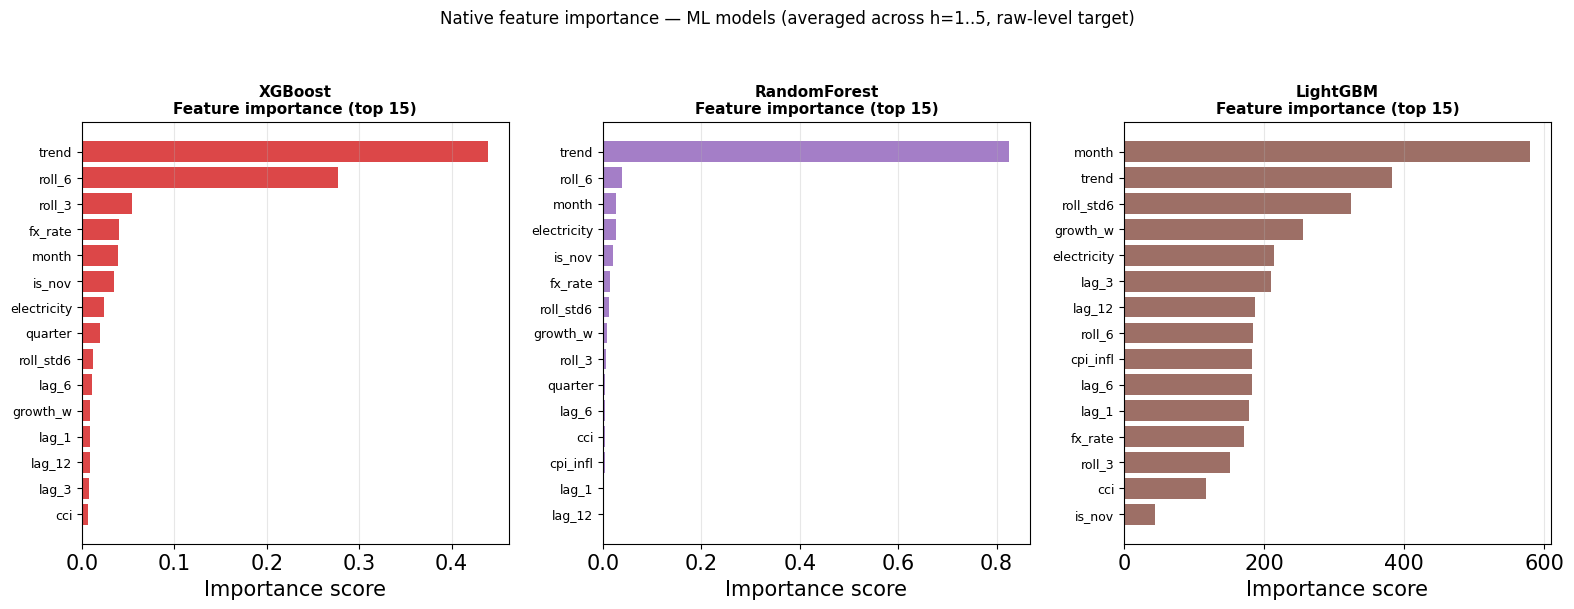

Saved -> plot_feature_importance.png

Top-5 by model:
  XGBoost      : trend=0.440, roll_6=0.277, roll_3=0.054, fx_rate=0.040, month=0.039
  RandomForest : trend=0.826, roll_6=0.038, month=0.026, electricity=0.026, is_nov=0.020
  LightGBM     : month=580.400, trend=382.000, roll_std6=323.600, growth_w=256.000, electricity=214.800


In [26]:
# ─── SECTION 7a : NATIVE FEATURE IMPORTANCE (XGBoost / RF / LightGBM) ────────
print("=" * 65); print("SECTION 7a — Native feature importance (averaged over h=1..5)"); print("=" * 65)

def average_feature_importance(model_factory, frame, feature_cols, origin_position, horizons=HORIZONS):
    """Fit one tree model per horizon (TREE_TARGET) and average feature_importances_."""
    feature_matrix = frame[feature_cols]; target_values = frame[TARGET_COL].values; n_rows = len(frame)
    importance_stack = []
    for horizon in horizons:
        train_positions = [i for i in range(n_rows)
                           if i + horizon <= origin_position and i + horizon - 12 >= 0
                           and feature_matrix.iloc[i].notna().all()
                           and not np.isnan(target_values[i + horizon])]
        anchor_train = np.array([target_values[i + horizon - 12] for i in train_positions])
        level_train  = target_values[[i + horizon for i in train_positions]]
        fit_target   = level_train / anchor_train if TREE_TARGET == "ratio" else level_train
        model = model_factory(); model.fit(feature_matrix.iloc[train_positions].values, fit_target)
        if hasattr(model, "feature_importances_"):
            importance_stack.append(model.feature_importances_)
    return (pd.Series(np.mean(importance_stack, axis=0), index=feature_cols)
            if importance_stack else pd.Series(dtype=float))

short_labels = {
    "retail_lag_1": "lag_1", "retail_lag_3": "lag_3", "retail_lag_6": "lag_6",
    "retail_lag_12": "lag_12", "retail_roll_3": "roll_3", "retail_roll_6": "roll_6",
    "retail_roll_std6": "roll_std6", "retail_growth_winsor": "growth_w",
    "cpi_signal": "cpi_infl" if CPI_MODE == "yoy" else "cpi_level", "electricity": "electricity",
    "exchange_rate": "fx_rate", "cci_level": "cci", "is_december": "is_dec",
    "is_november": "is_nov", "is_april": "is_apr",
}
importance_by_model = {
    "XGBoost":      average_feature_importance(make_xgboost, data, FEATURE_COLS, origin_pos),
    "RandomForest": average_feature_importance(make_random_forest, data, FEATURE_COLS, origin_pos),
    "LightGBM":     average_feature_importance(make_lightgbm, data, FEATURE_COLS, origin_pos),
}
panel_colors = {"XGBoost": "#d62728", "RandomForest": "#9467bd", "LightGBM": "#8c564b"}

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for axis, (model_name, importance_series) in zip(axes, importance_by_model.items()):
    top15 = importance_series.sort_values(ascending=True).tail(15)
    top15.index = [short_labels.get(name, name) for name in top15.index]
    axis.barh(range(len(top15)), top15.values, color=panel_colors[model_name], alpha=0.85)
    axis.set_yticks(range(len(top15))); axis.set_yticklabels(top15.index, fontsize=9)
    axis.set_title(f"{model_name}\nFeature importance (top 15)", fontsize=11, fontweight="bold")
    axis.set_xlabel("Importance score"); axis.grid(True, axis="x", alpha=0.3)
plt.suptitle("Native feature importance — ML models (averaged across h=1..5, raw-level target)",
             fontsize=12, y=1.02)
plt.tight_layout(); plt.savefig("plot_feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()
print("Saved -> plot_feature_importance.png")
print("\nTop-5 by model:")
for model_name, importance_series in importance_by_model.items():
    ranked = importance_series.sort_values(ascending=False).head(5)
    print(f"  {model_name:<13s}: " + ", ".join(f"{short_labels.get(k,k)}={v:.3f}" for k, v in ranked.items()))


SECTION 7b — SHAP explainability (XGBoost, best tree)


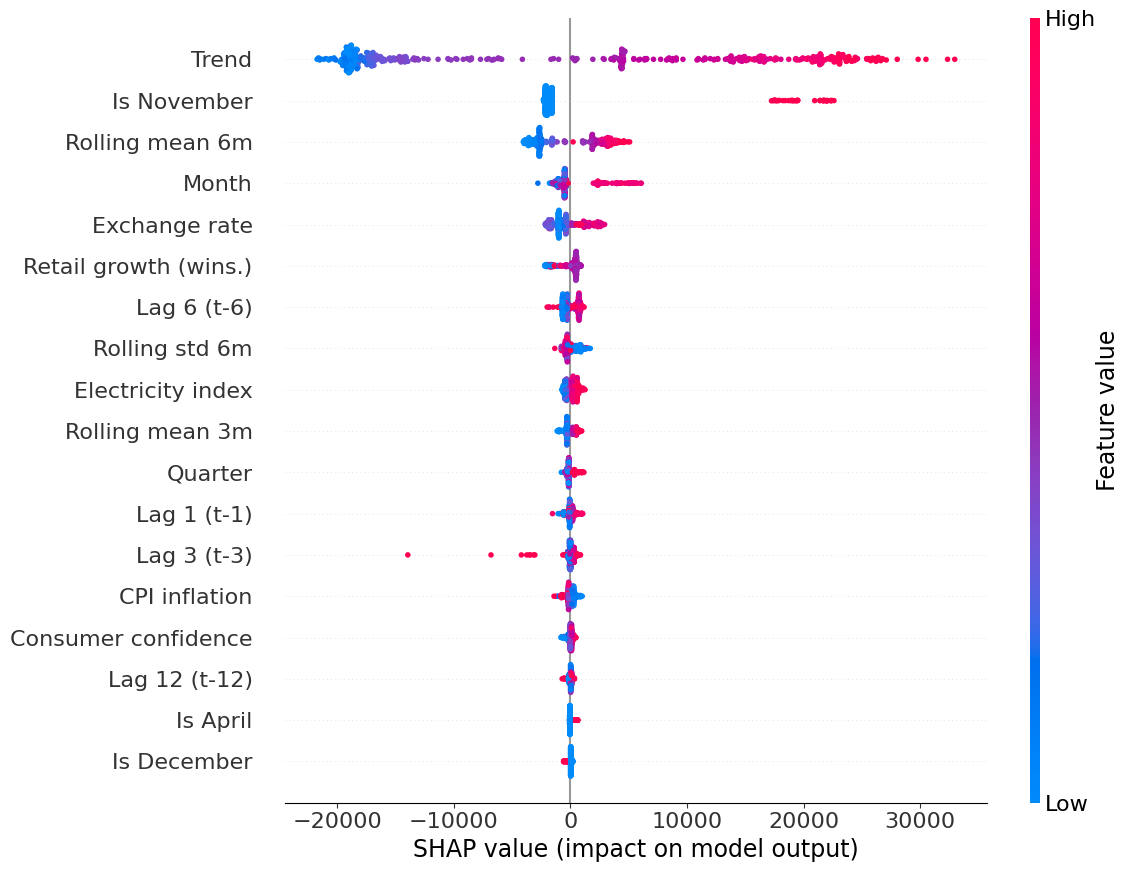

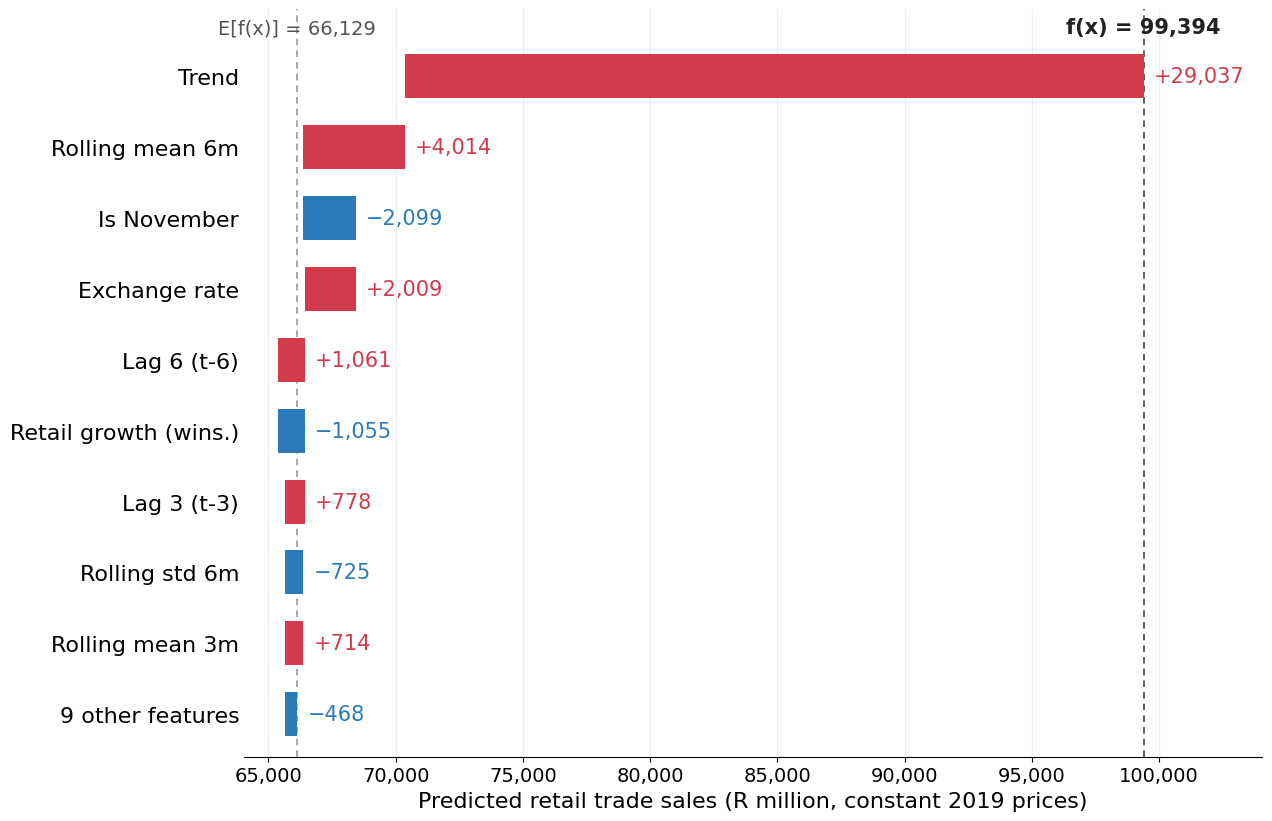


Mean |SHAP| ranking (top drivers of the level forecast):
Trend                    16082.509766
Is November               3365.620117
Rolling mean 6m           2858.530029
Month                     1204.290039
Exchange rate             1183.880005
Retail growth (wins.)      661.640015
Lag 6 (t-6)                587.000000
Rolling std 6m             427.970001
Electricity index          411.910004
Rolling mean 3m            400.079987
Quarter                    271.519989
Lag 1 (t-1)                252.960007
Lag 3 (t-3)                245.960007
CPI inflation              239.660004
Consumer confidence        128.779999
Lag 12 (t-12)               80.589996
Is April                    79.550003
Is December                 72.209999

Saved: fig4a_shap_beeswarm.png, fig4b_shap_waterfall.png/.pdf


In [27]:
# ─── SECTION 7b : SHAP EXPLAINABILITY (best tree model; enlarged figures) ────
# SHAP (TreeExplainer) needs a tree model, so it explains the best TREE on the
# walk-forward, independent of the conformal model (which is now pure SARIMA).
tree_model_factories = globals().get("tree_model_factories",
    {"XGBoost": make_xgboost, "RandomForest": make_random_forest, "LightGBM": make_lightgbm})
_trees = walk_forward[walk_forward.model.isin(list(tree_model_factories))]
shap_model = (_trees.groupby(["model", "horizon"])["ape"].median().groupby("model").mean().idxmin())
print("\n" + "=" * 65); print(f"SECTION 7b — SHAP explainability ({shap_model}, best tree)"); print("=" * 65)

_, shap_h1_model, shap_h1_train_matrix = fit_direct_multistep(
    tree_model_factories[shap_model], data, FEATURE_COLS, origin_pos,
    horizons=[1], return_h1_model=True)
readable_names = {
    "retail_lag_1": "Lag 1 (t-1)", "retail_lag_3": "Lag 3 (t-3)", "retail_lag_6": "Lag 6 (t-6)",
    "retail_lag_12": "Lag 12 (t-12)", "retail_roll_3": "Rolling mean 3m", "retail_roll_6": "Rolling mean 6m",
    "retail_roll_std6": "Rolling std 6m", "retail_growth_winsor": "Retail growth (wins.)",
    "cpi_signal": "CPI inflation" if CPI_MODE == "yoy" else "CPI level", "electricity": "Electricity index",
    "exchange_rate": "Exchange rate", "cci_level": "Consumer confidence", "trend": "Trend",
    "month": "Month", "quarter": "Quarter", "is_december": "Is December",
    "is_november": "Is November", "is_april": "Is April",
}
feature_labels = [readable_names.get(c, c) for c in FEATURE_COLS]
explainer = shap.TreeExplainer(shap_h1_model)
shap_values = explainer.shap_values(shap_h1_train_matrix.values)

from matplotlib.ticker import FuncFormatter
# (a) Figure 4.8: global beeswarm, no title, larger text
plt.rcParams.update({"font.size": 16})
plt.figure(figsize=(12, 9))
shap.summary_plot(shap_values, shap_h1_train_matrix.values, feature_names=feature_labels,
                  show=False, max_display=18, plot_size=(12, 9))
fig = plt.gcf()
for a in fig.axes:
    a.tick_params(labelsize=16)
    a.xaxis.label.set_size(17)
    a.yaxis.label.set_size(17)
plt.tight_layout(); plt.savefig("fig4a_shap_beeswarm.png", dpi=200, bbox_inches="tight"); plt.show()

# (b) Figure 4.9: waterfall, no title, larger text
origin_row = data[FEATURE_COLS].iloc[[origin_pos]].values
vals = explainer.shap_values(origin_row)[0]
base = float(explainer.expected_value); pred = float(shap_h1_model.predict(origin_row)[0])
order = np.argsort(np.abs(vals))[::-1]; K = 9
top = order[:K]; other = vals[order[K:]].sum()
labels = [feature_labels[i] for i in top] + [f"{len(order) - K} other features"]
contr = [vals[i] for i in top] + [other]; M = len(contr)
starts = [0.0] * M; running = base
for yy in range(M):
    li = M - 1 - yy; starts[li] = running; running += contr[li]
span = pred - base if pred != base else 1.0
fig, ax = plt.subplots(figsize=(13, 8.5)); RED = "#d13b4a"; BLUE = "#2b7bba"
for li in range(M):
    yy = M - 1 - li; c = contr[li]; s = starts[li]; col = RED if c >= 0 else BLUE
    ax.barh(yy, c, left=s, color=col, height=0.62, zorder=3)
    right = max(s, s + c)
    ax.text(right + span * 0.012, yy, (f"+{c:,.0f}" if c >= 0 else f"−{abs(c):,.0f}"),
            va="center", ha="left", color=col, fontsize=15, zorder=5)
ax.axvline(base, color="#999", ls=(0, (4, 3)), lw=1.2); ax.axvline(pred, color="#444", ls=(0, (4, 3)), lw=1.2)
ax.set_yticks(range(M)); ax.set_yticklabels(labels[::-1], fontsize=16); ax.set_ylim(-0.6, M - 0.05)
ax.annotate(f"E[f(x)] = {base:,.0f}", xy=(base, M - 0.45), ha="center", va="bottom", color="#555", fontsize=14)
ax.annotate(f"f(x) = {pred:,.0f}", xy=(pred, M - 0.45), ha="center", va="bottom", color="#222", fontsize=15, fontweight="bold")
ax.set_xlabel("Predicted retail trade sales (R million, constant 2019 prices)", fontsize=16)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))
ax.tick_params(axis="x", labelsize=14)
ax.grid(axis="x", color="#eee", zorder=0)
for sp in ["top", "right", "left"]: ax.spines[sp].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_xlim(min(starts) - span * 0.04, max([s + c for s, c in zip(starts, contr)] + [pred]) + span * 0.14)
plt.tight_layout()
plt.savefig("fig4b_shap_waterfall.png", dpi=220, bbox_inches="tight", pad_inches=0.25)
plt.savefig("fig4b_shap_waterfall.pdf", bbox_inches="tight", pad_inches=0.25); plt.show()

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_labels).sort_values(ascending=False)
print("\nMean |SHAP| ranking (top drivers of the level forecast):")
print(mean_abs_shap.round(2).to_string())
print("\nSaved: fig4a_shap_beeswarm.png, fig4b_shap_waterfall.png/.pdf")
